# Prot2GO: Enhancing Protein Function Annotation with Hierarchical Graph Neural Networks

Author: Cleverson M., PhD

## Setting the Environment

### Importing Modules

In [82]:
# Importing modules

# Core modules
import os
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import string
import re
from concurrent.futures import ThreadPoolExecutor
import requests
import warnings
import powerlaw
from itertools import product

# Stats
from scipy.stats import gaussian_kde

# Plotting and Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px

# Clustering
from yellowbrick.cluster import KElbowVisualizer
import hdbscan
import umap.umap_ as umap

# Bio and networks
from Bio import SeqIO
from obonet import read_obo
import networkx as nx

# PyTorch
import torch
import torch.nn.functional as F
from torch.nn import Dropout
from torch.utils.data import Dataset, DataLoader, TensorDataset

# PyG
from torch_geometric.utils import (
    structured_negative_sampling_feasible,
    degree,
    to_undirected,
)
from torch_geometric.data import Data, HeteroData
from torch_geometric.nn import GATConv, Linear

# Huggingface
from transformers import BertTokenizer, BertModel
from sentence_transformers import SentenceTransformer

# Sklearn
from sklearn.metrics import (
    roc_auc_score,
    ConfusionMatrixDisplay,
    classification_report,
    silhouette_score,
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.manifold import SpectralEmbedding, TSNE

# Model performance logging
import wandb

# Disable warnings
warnings.filterwarnings("ignore")

# Set wandb environment variable
os.environ["WANDB_NOTEBOOK_NAME"] = "model_gat.ipynb"

# Set CUDA and PyTorch environment
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.environ["TORCH"] = torch.__version__

# Check PyTorch and CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA version: {torch.version.cuda}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device: {device}")

PyTorch version: 2.3.0
CUDA version: 12.1
CUDA available: True
Device: cuda


### Project Folders

In [2]:
# Create project folders and define global paths

# Define project root path
root = Path("/home/clever/datascience/projects/prot2go")

# Define data path
data_folder = root / "data"

# Create folder to save GO data
go_folder = data_folder / "go"
go_folder.mkdir(parents=True, exist_ok=True)

# Create folder to save results by species
results_folder = root / "results"
results_folder.mkdir(parents=True, exist_ok=True)

# List of species (PPI data)
species = [
    "human",
    "yeast",
    "ecoli",
    "mouse",
    "elegans",
    "droso",
    "benchmark",
]

# Base directories for storing species results
base_directories = [
    "eda",  # EDA of protein and PPI data
    "metadata",  # protein and PPI metadata
    "datasets",  # protein embeddings and PPI torch datasets
]

# Create the directory structure
for specie in species:
    for base_dir in base_directories:
        folder_path = results_folder / specie / base_dir
        folder_path.mkdir(parents=True, exist_ok=True)

# Create paths to species' folders
human_folder = results_folder / "human"
ecoli_folder = results_folder / "ecoli"
yeast_folder = results_folder / "yeast"
mouse_folder = results_folder / "mouse"
elegans_folder = results_folder / "elegans"
droso_folder = results_folder / "droso"
benchmark_folder = results_folder / "benchmark"

# Define species to analyze in the session
species_folder = human_folder
print(species_folder)

/home/clever/datascience/projects/prot2go/results/human


### Custom Functions

#### Create GO dataframe from GO Graph

In [3]:
# Preprocess GO graph

def process_node(item):
    """
    Extracts Gene Ontology (GO) Directed Acyclic Graph (DAG) node data.

    This function processes a given GO term and its attributes, extracts the definition,
    and returns relevant information about the GO term.

    Args:
        item (tuple): A tuple containing the GO term (str) and its attributes (dict).

    Returns:
        dict: A dictionary containing the GO term ID, name, namespace, original definition,
              and definition word count.
    """
    go_term, attr = item
    # Extract the definition text
    definition = attr["def"].split('"', 2)[1] if "def" in attr else ""
    return {
        "go_id": go_term,
        "name": attr["name"],
        "namespace": attr["namespace"],
        "definition": definition,
        "def_word_count": len(re.findall(r"\w+", definition)),
    }


def create_go_dataframe(go_graph):
    """
    Creates a DataFrame from the GO graph nodes.

    Args:
        go_graph: A GO graph object containing nodes with GO terms and attributes.

    Returns:
        pd.DataFrame: A DataFrame containing the processed information of GO terms.
    """
    with ThreadPoolExecutor(
        max_workers=16
    ) as executor:  # Increase max_workers if you have more CPU cores
        results = list(
            tqdm(
                executor.map(process_node, go_graph.nodes.items()),
                total=len(go_graph.nodes),
                desc="Processing GO graph nodes...",
            )
        )

    # Create DataFrame from results
    go_df = pd.DataFrame(results)
    return go_df

#### PPI Data Preprocessing (DIP database)

In [4]:
# Functions to extract data from DIP datasets

def extract_uniprot_ids(field):
    """
    Extracts the UniProt ID from a given field.

    Parameters:
    field (str): A string containing UniProt IDs in the format "uniprotkb:ID".

    Returns:
    str or None: The extracted UniProt ID or None if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    for uniprot_id in split_field:
        if uniprot_id.startswith("uniprotkb"):
            return uniprot_id.split(":")[1]
    return None


def extract_methods(field):
    """
    Extracts methods enclosed in parentheses from a given field.

    Parameters:
    field (str): A string containing methods in the format "method (detail)".

    Returns:
    str: Semi-colon separated methods or an empty string if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_list = [
        re.search(r"\((.*?)\)", method).group(1)
        for method in split_field
        if re.search(r"\((.*?)\)", method)
    ]
    return ";".join(fragment_list) if fragment_list else ""


def extract_taxiIDs(field):
    """
    Extracts the first numeric ID from a given field.

    Parameters:
    field (str): A string containing numeric IDs.

    Returns:
    str or None: The extracted ID or None if not found.
    """
    if pd.isna(field):
        return None
    pattern = re.compile(r"\b\d+\b")
    match = pattern.search(field)
    return match.group(0) if match else None


def extract_ppi_type(field):
    """
    Extracts unique PPI types enclosed in parentheses from a given field.

    Parameters:
    field (str): A string containing PPI types in the format "type (detail)".

    Returns:
    str: Semi-colon separated unique PPI types or an empty string if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_set = {
        re.search(r"\((.*?)\)", ppi_type).group(1)
        for ppi_type in split_field
        if re.search(r"\((.*?)\)", ppi_type)
    }
    return ";".join(fragment_set) if fragment_set else ""


def extract_confidence_score(field):
    """
    Extracts the confidence score from a given field.

    Parameters:
    field (str): A string containing confidence score in the format "label:score".

    Returns:
    str or None: The extracted confidence score or None if not found.
    """
    if pd.isna(field):
        return None
    parts = field.split(":")
    return parts[1] if len(parts) > 1 else None

#### Evaluate Model Performance

In [5]:
# Evaluating model performance

# Evaluate train and validation during training
def evaluate(model, x_dict, edge_index_dict, edge_labels, val_mask, device="cuda"):
    model.to(device)
    for key in x_dict:
        x_dict[key] = x_dict[key].to(device)
    for key in edge_index_dict:
        edge_index_dict[key] = edge_index_dict[key].to(device)
    edge_labels = edge_labels.to(device)
    val_mask = val_mask.to(device)

    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, val_mask)
        val_loss = F.binary_cross_entropy_with_logits(out, edge_labels[val_mask])
        predictions = out.sigmoid()
        val_auroc = roc_auc_score(
            edge_labels[val_mask].cpu().numpy(),
            predictions.cpu().numpy(),
        )
    return val_loss.item(), val_auroc

# Evaluate model performance (test)
def predict(model, x_dict, edge_index_dict, edge_labels, mask, device="cuda"):
    model.to(device)
    for key in x_dict:
        x_dict[key] = x_dict[key].to(device)
    for key in edge_index_dict:
        edge_index_dict[key] = edge_index_dict[key].to(device)
    edge_labels = edge_labels.to(device)
    mask = mask.to(device)

    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, mask)
        probabilities = out.sigmoid()

        true_labels = edge_labels[mask]

        auroc = roc_auc_score(true_labels.cpu().numpy(), probabilities.cpu().numpy())

        predicted_labels = (probabilities > 0.5).float()

        return predicted_labels, true_labels, auroc, probabilities


def evaluate_model_performance(
    model,
    hetero_data,
    associations_df,
    go_id_map,
    save_path,
    device="cuda" if torch.cuda.is_available() else "cpu",
):
    # Ensure Path object of save path
    save_path = Path(save_path)

    # Move model and data to device
    model.to(device)
    for key in hetero_data.x_dict:
        hetero_data.x_dict[key] = hetero_data.x_dict[key].to(device)
    for key in hetero_data.edge_index_dict:
        hetero_data.edge_index_dict[key] = hetero_data.edge_index_dict[key].to(device)
    hetero_data["protein", "associates_with", "go"].edge_label = hetero_data[
        "protein", "associates_with", "go"
    ].edge_label.to(device)
    hetero_data["protein", "associates_with", "go"].test_mask = hetero_data[
        "protein", "associates_with", "go"
    ].test_mask.to(device)

    # Extract test mask
    test_mask = hetero_data["protein", "associates_with", "go"].test_mask

    # Predict
    predicted_labels, test_labels, test_auroc, probabilities = predict(
        model,
        hetero_data.x_dict,
        hetero_data.edge_index_dict,
        hetero_data["protein", "associates_with", "go"].edge_label,
        test_mask,
        device=device,
    )

    # Retrieve the indices of the test edges
    test_edge_indices = hetero_data["protein", "associates_with", "go"].edge_index[
        :, test_mask
    ]

    # Get the protein and GO indices
    protein_indices = test_edge_indices[0].cpu().numpy()
    go_indices = test_edge_indices[1].cpu().numpy()

    # Map indices to IDs
    protein_id_map = dict(
        zip(
            associations_df["uniprot_idx"].astype(int),
            associations_df["uniprot_id"],
        )
    )
    go_id_map = {v: k for k, v in go_id_map.items()}  # swap mapping

    # Prepare data for the DataFrame
    data = {
        "Protein ID": [protein_id_map.get(idx, "Unknown") for idx in protein_indices],
        "GO ID": [go_id_map.get(idx, "Unknown") for idx in go_indices],
        "Ground Truth Label": [label.item() for label in test_labels],
        "Predicted Label": [label.item() for label in predicted_labels],
        "Probability": [prob.item() for prob in probabilities],
    }

    # Create and save df
    results_df = pd.DataFrame(data)
    results_df.to_csv(save_path / "test_results.csv", index=False)

    # Plot metrics
    print(f"AUROC test: {test_auroc:.2f}")

    # Save classification report and print
    class_report = classification_report(
        test_labels.cpu().numpy(),
        predicted_labels.cpu().numpy(),
        target_names=["0", "1"],
    )

    with open(save_path / "classification_report.txt", "w") as file:
        file.write(class_report)

    print("\nClassification Report:")
    print(class_report)

    disp = ConfusionMatrixDisplay.from_predictions(
        test_labels.cpu().numpy(),
        predicted_labels.cpu().numpy(),
        normalize="true",
        cmap="Blues",
        values_format=".1%",
    )
    plt.savefig(save_path / "confusion_matrix.png", dpi=300)
    plt.show()

    return results_df

#### Extract and Visualize Attention Weights

**Notes for improvements**:
- Averaging src and dst attention weights ensures that attention is equally split between outgoing and incoming edges.
  - *The procedure can be adjust according to specific cases, maybe checking src and dst attentions separatelly to get insights .*

In [6]:
# Extract and visualize attentions

def aggregate_attention_weights(attn_weights, edge_index, num_nodes):
    """
    Aggregate attention weights for each node based on the given edge_index.
    """
    node_attention = torch.zeros(
        (num_nodes, attn_weights.size(1)), device=attn_weights.device
    )
    assert edge_index.size(1) == attn_weights.size(
        0
    ), "Dimension mismatch between edge_index and attn_weights"

    # Use scatter_add for efficient aggregation of attention weights
    src = edge_index[0]
    dst = edge_index[1]
    node_attention.index_add_(0, src, attn_weights)
    node_attention.index_add_(0, dst, attn_weights)

    return node_attention / 2  # average


def visualize_node_importance(
    attn_weights, node_type, id_mapping, conv_layer, top_n=10
):
    """
    Visualize the importance of nodes based on aggregated attention weights using Plotly.
    """
    if attn_weights is None or not attn_weights.numel():
        print("Attention weights are empty or invalid.")
        return [], None

    attn_weights = attn_weights.mean(dim=1).cpu().detach().numpy()
    valid_weights = np.where(np.isfinite(attn_weights), attn_weights, 0)

    if not np.any(valid_weights):
        print("All attention weights are zero or invalid.")
        return [], None

    top_indices = np.argsort(valid_weights)[-top_n:][::-1]
    top_ids = [id_mapping[idx] for idx in top_indices]

    fig = go.Figure(data=[go.Bar(x=top_ids, y=valid_weights[top_indices])])

    fig.update_layout(
        title={
            'text': f"Top {top_n} Important {node_type} Nodes (GATconv Layer {conv_layer})",
            'y':0.9,
            'x':0.5,
            'xanchor': 'center',
            'yanchor': 'top',
            'font': {'size': 20}
        },
        xaxis_title=f"Top {top_n} {node_type} Node IDs",
        yaxis_title="Importance",
        xaxis_tickangle=-45,
        xaxis=dict(
            showgrid=False,
            zeroline=False,
            showline=True,
            linewidth=2,
            linecolor='black',
            mirror=True
        ),
        yaxis=dict(
            showgrid=False,
            zeroline=False,
            showline=True,
            linewidth=2,
            linecolor='black',
            mirror=True
        ),
        plot_bgcolor='white',
        font=dict(
            family="Arial, sans-serif",
            size=12,
            color="black"
        ),
        width=800,
        height=600,

    )
    return top_ids, fig


def plot_node_importance(model, hetero_data, save_path, top_n=25):
    """
    Main function to process and plot node importance for different node types using Plotly.
    """

    # Ensure Path object of save path
    save_path = Path(save_path)
    (
        (edge_index_protein_1, attn_weights_protein_1),
        (edge_index_go_1, attn_weights_go_1),
        (edge_index_protein_2, attn_weights_protein_2),
        (edge_index_go_2, attn_weights_go_2),
    ) = model.get_attention_weights(hetero_data.x_dict, hetero_data.edge_index_dict)

    id_mappings = {
        "protein": {idx: id for idx, id in enumerate(hetero_data["protein"].id)},
        "go": {idx: id for idx, id in enumerate(hetero_data["go"].id)},
    }

    results = {}
    plots = []
    for node_type, attn_weights_list, edge_indices_list in [
        (
            "protein",
            [attn_weights_protein_1, attn_weights_protein_2],
            [edge_index_protein_1, edge_index_protein_2],
        ),
        (
            "go",
            [attn_weights_go_1, attn_weights_go_2],
            [edge_index_go_1, edge_index_go_2],
        ),
    ]:
        for i, (attn, edges) in enumerate(zip(attn_weights_list, edge_indices_list), 1):
            attention = aggregate_attention_weights(
                attn, edges, hetero_data[node_type].x.size(0)
            )
            top_ids, fig = visualize_node_importance(
                attention,
                node_type.capitalize(),
                id_mappings[node_type],
                conv_layer=i,
                top_n=top_n,
            )
            if fig is not None:
                fig.write_image(str(save_path / f"{node_type}_importance_{i}.png"))
                plots.append(fig)
            results[f"{node_type}_{i}"] = top_ids

    for key, ids in results.items():
        print(f"Top nodes by importance for {key}:")
        print(ids)

    return results, plots


def compare_degrees(important_nodes, node_type, edge_index, id_mapping, save_path):
    """
    Compare the degrees of the important nodes with their actual degrees.

    Parameters:
    - important_nodes: List of important node IDs.
    - node_type: Type of the node ('Protein' or 'GO Term').
    - edge_index: Edge index tensor from the graph.
    - id_mapping: Dictionary mapping node indices to their IDs.

    Returns:
    - DataFrame showing the comparison of degrees.
    """

    # Ensures Path object
    save_path = Path(save_path)
    # Convert id_mapping to index-based mapping for quick lookup
    index_mapping = {v: k for k, v in id_mapping.items()}

    # Get the indices of the important nodes
    important_indices = [index_mapping[node_id] for node_id in important_nodes]

    # Calculate the degrees for all nodes
    row, col = edge_index
    node_degrees = degree(row, row.max().item() + 1).cpu().numpy()

    # Get the degrees of the important nodes
    important_degrees = [node_degrees[idx] for idx in important_indices]

    # Create a DataFrame for comparison
    comparison_df = pd.DataFrame(
        {"Node ID": important_nodes, "Degree": important_degrees}
    )

    # Plot the comparison
    plt.figure(figsize=(12, 6))
    plt.bar(comparison_df["Node ID"], comparison_df["Degree"])
    plt.xlabel(f"{node_type} Node IDs")
    plt.ylabel("Degree")
    plt.title(f"Degree Comparison of Important {node_type} Nodes")
    plt.xticks(rotation=90)
    plt.savefig(save_path / f"degree_comparison_attention_{node_type}.png")
    plt.show()

    return comparison_df

#### Analyze IA and Tokens Enriched in top attn GO terms

In [7]:
# Analyze the distribution of IA across GO terms and key tokens in top GO nodes


def plot_tfidf(df, text_col, label, top_n=25):
    """
    Computes and plots TF-IDF of definitions.

    Parameters:
    - df (pd.DataFrame): DataFrame containing GO terms with preprocessed definitions.
    - text_col (str): Column name for preprocessed text data.
    - label (str): Label for the plot title.
    - top_n (int): Number of top terms to visualize with TF-IDF.

    Returns:
    - list: List of top tokens based on TF-IDF scores.
    """
    vectorizer = TfidfVectorizer(max_df=0.85, min_df=2, ngram_range=(1, 2))
    tf_idf_matrix = vectorizer.fit_transform(df[text_col])
    max_scores = np.max(tf_idf_matrix, axis=0).toarray().flatten()
    sorted_indices = np.argsort(max_scores)[::-1][:top_n]
    sorted_features = vectorizer.get_feature_names_out()[sorted_indices]
    sorted_scores = max_scores[sorted_indices]

    plt.figure(figsize=(12, 8))
    plt.barh(sorted_features, sorted_scores, color="green")
    plt.xlabel("Max TF-IDF Score")
    plt.title(f"Top {top_n} Terms with Highest TF-IDF Scores in {label}")
    plt.gca().invert_yaxis()
    plt.show()

    return sorted_features.tolist()


def plot_kde_with_overlay(df, top_go_df, information_accretion_col, label):
    """
    Plots KDE of 'ia' for all GO terms with overlay of top GO terms.

    Parameters:
    - df (pd.DataFrame): DataFrame containing all GO terms.
    - top_go_df (pd.DataFrame): DataFrame containing top GO terms.
    - information_accretion_col (str): Column name for the IA values.
    - label (str): Label for the plot title.
    """
    plt.figure(figsize=(12, 6))
    sns.kdeplot(
        df[information_accretion_col], fill=True, alpha=0.5, label="All GO Terms"
    )
    sns.rugplot(
        top_go_df[information_accretion_col],
        height=0.1,
        color="red",
        label="Top GO Terms",
    )
    plt.title(
        f"Distribution of 'ia' across all GO terms with overlay of top GO terms - {label}"
    )
    plt.xlabel("ia")
    plt.ylabel("Density")
    plt.legend()
    plt.show()


def plot_heatmap(
    df, top_go_ids_conv1, top_go_ids_conv2, information_accretion_col, top_n=25
):
    """
    Plots a heatmap of IA values for random GO terms, top GO terms from conv1, and top GO terms from conv2.

    Parameters:
    - df (pd.DataFrame): DataFrame containing GO terms with IA values.
    - top_go_ids_conv1 (list): List of top GO IDs from conv1.
    - top_go_ids_conv2 (list): List of top GO IDs from conv2.
    - information_accretion_col (str): Column name for the IA values.
    - top_n (int): Number of top terms to visualize.
    """
    # Filter DataFrame to get top GO terms
    top_go_df_conv1 = df[df["go_id"].isin(top_go_ids_conv1)]
    top_go_df_conv2 = df[df["go_id"].isin(top_go_ids_conv2)]

    num_top_terms = len(top_go_df_conv1)

    # Select random GO terms for comparison
    random_go_df = df[~df["go_id"].isin(top_go_ids_conv1 + top_go_ids_conv2)].sample(
        n=num_top_terms, random_state=42
    )

    # Combine the top and random GO terms for visualization
    combined_df = pd.concat([random_go_df, top_go_df_conv1, top_go_df_conv2])
    combined_df["Category"] = (
        ["Random GO Terms"] * num_top_terms
        + ["Top GO Terms Conv1"] * num_top_terms
        + ["Top GO Terms Conv2"] * num_top_terms
    )

    # Create a heatmap
    plt.figure(figsize=(12, 0.8 * top_n))
    ia_matrix = combined_df.pivot_table(
        index="go_id", columns="Category", values=information_accretion_col
    )
    sns.heatmap(ia_matrix, annot=True, cmap="viridis", cbar_kws={"label": "IA Value"})
    plt.title("Heatmap of IA Values for Random GO Terms, Conv1, and Conv2 Top GO Terms")
    plt.xlabel("Category")
    plt.ylabel("GO Term ID")
    plt.show()


def analyze_top_go(
    df, results, information_accretion_col="ia", text_col="definition", top_n=25
):
    """
    Main function to analyze and plot TF-IDF, histogram, and heatmap for top GO terms from two convolution layers.

    Parameters:
    - df (pd.DataFrame): DataFrame containing GO terms.
    - results (dict): Dictionary containing top proteins and top GO terms for two convolution layers.
    - information_accretion_col (str): Column name for the IA values (default 'ia').
    - text_col (str): Column name for preprocessed text data (default 'definition').
    - top_n (int): Number of top terms to visualize with TF-IDF.

    Returns:
    - Tuple containing:
        - List of top tokens for conv1.
        - List of top tokens for conv2.
        - DataFrame filtered to top GO terms for conv1.
        - DataFrame filtered to top GO terms for conv2.
    """
    # Analyze and plot for conv1
    top_go_df_conv1 = df[df["go_id"].isin(results["go_1"])]
    plot_kde_with_overlay(
        df, top_go_df_conv1, information_accretion_col, label="Conv 1"
    )

    top_tokens_conv1 = plot_tfidf(
        top_go_df_conv1, text_col, label="Top GO Terms Conv1", top_n=top_n
    )

    # Analyze and plot for conv2
    top_go_df_conv2 = df[df["go_id"].isin(results["go_2"])]
    plot_kde_with_overlay(
        df, top_go_df_conv2, information_accretion_col, label="Conv 2"
    )

    top_tokens_conv2 = plot_tfidf(
        top_go_df_conv2, text_col, label="Top GO Terms Conv2", top_n=top_n
    )

    # Plot heatmap for comparison
    plot_heatmap(
        df, results["go_1"], results["go_2"], information_accretion_col, top_n=top_n
    )

    return top_tokens_conv1, top_tokens_conv2, top_go_df_conv1, top_go_df_conv2

### Custom Classes

#### ProteinDataset Class

In [8]:
class ProteinDataset(Dataset):
    """
    A PyTorch Dataset class for reading and preprocessing protein sequences for embedding generation.

    Attributes:
        dataframe (pd.DataFrame): A dataframe with UniProt IDs, protein sequences (1-letter a. a. code)
        and their sequence lengths (column names: "uniprot_id", "sequence", "lenght").

    Methods:
        __len__: Returns the number of files in the dataset.
        __getitem__: Retrieves a sequence and its identifier by index, applying preprocessing.
    """

    def __init__(self, dataframe):
        """
        Initializes the ProteinDataset with a dataframe.

        Parameters:
            dataframe (pd.DataFrame): A dataframe with UniProt IDs, protein sequences (1-letter a. a. code)
        and their sequence lengths (column names: "uniprot_id", "sequence", "lenght").
        """
        self.dataframe = dataframe

    def __len__(self):
        """
        Provides the size of the dataset.

        Returns:
            int: The number of sequences in the dataframe.
        """
        return len(self.dataframe)

    def __getitem__(self, idx):
        """
        Retrieves the sequence and its identifier at the specified index after preprocessing.

        Parameters:
            idx (int): The index of the sequence to retrieve.

        Returns:
            tuple: A tuple containing the preprocessed sequence and its id.
        """
        row = self.dataframe.iloc[idx]
        seq = " ".join(row["sequence"].replace(r"[UZOB]", "X"))

        return seq, row["uniprot_id"]

#### ProteinEmbedding Dataset Class

In [9]:
class ProteinEmbeddingDataset(Dataset):
    """
    A PyTorch Dataset for loading protein embeddings stored as .pt (PyTorch tensor) files.

    Each tensor file contains the embedding of a protein, identified by a UniProt ID. This dataset
    facilitates the access to these embeddings for model training or inference, ensuring each
    embedding is loaded as needed, thus optimizing memory usage.

    Attributes:
        tensor_folder (str): The directory path where the embedding tensors (.pt files) are stored.
        uniprot_ids (list): A list of UniProt IDs corresponding to the proteins for which embeddings are available.

    Methods:
        __len__: Returns the total number of embeddings available in the dataset.
        __getitem__: Retrieves an embedding by its index, along with its corresponding UniProt ID.

    Parameters:
        tensor_folder (str): Path to the folder where tensor files, representing protein embeddings, are stored.
                             Each file should be named with the UniProt ID of the protein it represents.
    """

    def __init__(self, tensor_folder):
        """
        Initializes the dataset with the path to the directory containing the embeddings.

        Args:
            tensor_folder (string): Path to the folder where tensors are stored.
        """
        self.tensor_folder = tensor_folder
        self.uniprot_ids = [
            file.split(".")[0]
            for file in os.listdir(tensor_folder)
            if file.endswith(".pt")
        ]

    def __len__(self):
        """
        Returns the total number of protein embeddings available.

        Returns:
            int: The count of UniProt ID-based tensor files in the tensor folder.
        """
        return len(self.uniprot_ids)

    def __getitem__(self, idx):
        """
        Retrieves a specific protein embedding and its corresponding UniProt ID by index.

        This method ensures that the embedding tensor is loaded from disk only when accessed,
        optimizing memory usage, especially useful when dealing with large datasets.

        Args:
            idx (int): The index of the protein embedding to retrieve.

        Returns:
            dict: A dictionary containing the UniProt ID ('uniprot_id') and the embedding tensor ('tensor').
                  The tensor is expected to have a shape of (1, 1024).

        Raises:
            AssertionError: If the loaded tensor does not match the expected shape of (1, 1024).
        """
        uniprot_id = self.uniprot_ids[idx]
        tensor_path = os.path.join(self.tensor_folder, uniprot_id + ".pt")
        tensor = torch.load(tensor_path)

        # Asserting the tensor is in the correct shape ensures consistency and prevents potential errors in downstream processes.
        assert tensor.shape == (
            1,
            1024,
        ), f"Tensor shape mismatch: {tensor.shape} != (1, 1024)"

        return {"uniprot_id": uniprot_id, "tensor": tensor}

#### Protein Sequence Embedding

In [10]:
def embed_sequences(
    dataframe: pd.DataFrame, out_dir: Path, per_residue=False, batch_size=1
):
    """
    Processes protein sequences from a folder, generating embeddings using a pre-trained BERT model.

    Parameters:
        dataframe (pd.DataFrame): A dataframe with protein IDs, corresponding peptide sequences and their lengths.
        per_residue (bool): If True, saves per-residue embeddings; otherwise, saves per-protein embeddings.
        batch_size (int): The batch size for processing sequences.
    """

    print(f"Loading transformer and tokenizer...")
    tokenizer = BertTokenizer.from_pretrained("Rostlab/prot_bert", do_lower_case=False)
    model = BertModel.from_pretrained("Rostlab/prot_bert")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device).half().eval()  # move model to gpu and set half-precision (float16)

    # Creates directories to save embeddings
    out_dir = Path(out_dir)  # ensures Path object
    out_dir.mkdir(parents=True, exist_ok=True)

    per_protein_path = out_dir / "per_protein"
    per_protein_path.mkdir(exist_ok=True, parents=True)

    per_residue_path = out_dir / "per_residue" if per_residue else None
    if per_residue_path:
        per_residue_path.mkdir(exist_ok=True, parents=True)

    # Reads fasta files in input folder
    dataset = ProteinDataset(dataframe)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for seqs, ids in tqdm(loader, desc="Embedding sequences"):
        for seq, seq_id in zip(seqs, ids):

            # Tokenize and move input tensors to the same device as the model
            inputs = tokenizer(seq, padding=True, truncation=True, return_tensors="pt")
            inputs = {key: tensor.to(device) for key, tensor in inputs.items()}

            with torch.no_grad():
                outputs = model(**inputs)
            protein_embeddings = outputs.last_hidden_state[
                :, : len(seq.replace(" ", "")) + 1
            ]

            # Detach and move to CPU before saving
            protein_embeddings = protein_embeddings.mean(dim=1).detach().cpu()
            torch.save(protein_embeddings, per_protein_path / f"{seq_id}.pt")

            if per_residue:
                residue_embeddings = outputs.last_hidden_state[
                    :, : len(seq.replace(" ", "")) + 1
                ]
                torch.save(
                    residue_embeddings.detach().cpu(),
                    per_residue_path / f"{seq_id}_res_embed.pt",
                )

    print(f"All proteins embedded successfully.")

#### Text Embedding with Sentence Transformer

In [24]:
class TextDataset(Dataset):
    def __init__(self, dataframe, text_column):
        self.texts = dataframe[text_column].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]


def embed_texts(df, column_id, column_text, pre_trained_model="all-MiniLM-L6-v2"):
    """
    Generates embeddings for text data in a DataFrame using a Sentence Transformer model.

    Parameters:
    - df (pandas.DataFrame): The DataFrame containing the text data.
    - column_id (str): The name of the column in the DataFrame that contains the identifiers for the text.
    - column_text (str): The name of the column in the DataFrame that contains the text to be embedded.

    Returns:
    - dict: A dictionary where the keys are entries from `column_id` and the values are the embeddings
            generated from the text in `column_text`.
    """
    # Load Sentence Transformer
    model = SentenceTransformer(pre_trained_model, device="cuda:0")

    # Create dataset from DataFrame
    dataset = TextDataset(df, column_text)
    dataloader = DataLoader(dataset, batch_size=128, shuffle=False)

    embeddings_dict = dict()
    for texts in tqdm(dataloader, total=len(dataloader)):
        embeddings = model.encode(
            texts, show_progress_bar=False, convert_to_tensor=True
        )
        for text, emb in zip(texts, embeddings):
            go_id = df[df[column_text] == text][column_id].values[0]
            embeddings_dict[go_id] = emb.cpu().numpy()

    print("All texts embedded successfully.")
    return embeddings_dict

#### Protein-GO Dataloader Class

In [12]:
class ProteinGoDataloader:
    def __init__(self, protein_ids_map, go_ids_map, species_folder):
        self.protein_ids_map = protein_ids_map
        self.go_ids_map = go_ids_map
        self.species_folder = Path(species_folder)
        self.edge_index_protgo_positive = None
        self.edge_index_protgo_negative = None
        self.associations_negative_df = None
        self.hetero_data = None
        self.train_mask = None
        self.val_mask = None
        self.test_mask = None
        self.train_protein_ids = None
        self.val_protein_ids = None
        self.test_protein_ids = None
        self.train_go_ids = None
        self.val_go_ids = None
        self.test_go_ids = None

    def generate_negative_edges(
        self,
        edge_index,
        num_nodes_protein,
        num_nodes_go,
        num_neg_samples,
        weighted=False,
        random_state=42,
        max_attempts_factor=10,
    ):
        rng = np.random.default_rng(random_state)
        existing_edges = set(map(tuple, edge_index.t().tolist()))

        if weighted:
            protein_degrees = np.zeros(num_nodes_protein, dtype=int)
            for protein_node, go_node in edge_index.t().tolist():
                protein_degrees[protein_node] += 1

        negative_samples = []
        attempts = 0
        max_attempts = num_neg_samples * max_attempts_factor
        neg_degree_count = np.zeros(num_nodes_protein, dtype=int) if weighted else None

        while len(negative_samples) < num_neg_samples and attempts < max_attempts:
            if weighted:
                protein_node = rng.choice(
                    num_nodes_protein, p=protein_degrees / protein_degrees.sum()
                )
            else:
                protein_node = rng.integers(0, num_nodes_protein)

            go_node = rng.integers(0, num_nodes_go)

            if (protein_node, go_node) not in existing_edges:
                negative_samples.append([protein_node, go_node])
                if weighted:
                    neg_degree_count[protein_node] += 1

            attempts += 1

        neg_sample_tensor = (
            torch.tensor(negative_samples, dtype=torch.long).t()
            if negative_samples
            else torch.empty((2, 0), dtype=torch.long)
        )

        protein_mapping = {v: k for k, v in self.protein_ids_map.items()}
        go_mapping = {v: k for k, v in self.go_ids_map.items()}

        mapped_negative_samples = [
            {
                "uniprot_id": protein_mapping.get(u_idx, None),
                "go_id": go_mapping.get(g_idx, None),
                "uniprot_idx": u_idx,
                "go_idx": g_idx,
            }
            for u_idx, g_idx in negative_samples
        ]

        self.associations_negative_df = pd.DataFrame(mapped_negative_samples)
        self.edge_index_protgo_negative = neg_sample_tensor

    def check_balance(
        self, positive_edge_index, negative_edge_index, num_nodes_protein, num_nodes_go
    ):
        protein_degrees_pos = np.zeros(num_nodes_protein, dtype=int)
        go_degrees_pos = np.zeros(num_nodes_go, dtype=int)
        for protein_node, go_node in positive_edge_index.t().tolist():
            protein_degrees_pos[protein_node] += 1
            go_degrees_pos[go_node] += 1

        protein_degrees_neg = np.zeros(num_nodes_protein, dtype=int)
        go_degrees_neg = np.zeros(num_nodes_go, dtype=int)
        for protein_node, go_node in negative_edge_index.t().tolist():
            protein_degrees_neg[protein_node] += 1
            go_degrees_neg[go_node] += 1

        plt.figure(figsize=(12, 6))
        plt.subplot(1, 2, 1)
        sns.kdeplot(
            protein_degrees_pos, color="blue", label="Positive", fill=True, alpha=0.5
        )
        sns.kdeplot(
            protein_degrees_neg, color="red", label="Negative", fill=True, alpha=0.5
        )
        plt.title("Protein Degree Distribution")
        plt.xlabel("Degree")
        plt.ylabel("Density")
        plt.legend()

        plt.subplot(1, 2, 2)
        sns.kdeplot(
            go_degrees_pos, color="blue", label="Positive", fill=True, alpha=0.5
        )
        sns.kdeplot(go_degrees_neg, color="red", label="Negative", fill=True, alpha=0.5)
        plt.title("GO Terms Degree Distribution")
        plt.xlabel("Degree")
        plt.ylabel("Density")
        plt.legend()

        plt.tight_layout()
        plt.savefig(self.species_folder / "balance_check.png", dpi=300)
        plt.show()

    def create_heterodata(
        self,
        protein_feats,
        go_feats,
        protein_ids,
        go_ids,
        edge_index_ppi,
        edge_index_go,
        edge_index_protgo_positive,
    ):
        
        # Make PPI graph undirected
        edge_index_ppi = to_undirected(edge_index_ppi)
        
        edge_index_protgo = torch.cat(
            (edge_index_protgo_positive, self.edge_index_protgo_negative), dim=1
        )
        positive_labels = torch.ones(
            edge_index_protgo_positive.shape[1], dtype=torch.float32
        )
        negative_labels = torch.zeros(
            self.edge_index_protgo_negative.shape[1], dtype=torch.float32
        )
        edge_labels = torch.cat((positive_labels, negative_labels), dim=0)

        hetero_data = HeteroData()
        hetero_data["protein"].x = protein_feats
        hetero_data["go"].x = go_feats
        hetero_data["protein"].id = protein_ids
        hetero_data["go"].id = go_ids
        hetero_data["protein", "ppi", "protein"].edge_index = edge_index_ppi
        hetero_data["go", "relation", "go"].edge_index = edge_index_go
        hetero_data["protein", "associates_with", "go"].edge_index = edge_index_protgo
        hetero_data["protein", "associates_with", "go"].edge_label = edge_labels

        self.hetero_data = hetero_data

    def split_dataset(self, train_ratio=0.6):
        val_ratio = (1 - train_ratio) / 2
        test_ratio = val_ratio
        assert isinstance(train_ratio, float), "Train ratio must be a float."
        assert 0 < train_ratio < 1, "Train ratio must be between 0 and 1."

        unique_proteins, edge_positions = torch.unique(
            self.hetero_data["protein", "associates_with", "go"].edge_index[0],
            return_inverse=True,
        )
        permuted_indices = torch.randperm(unique_proteins.size(0))
        num_proteins = unique_proteins.size(0)
        train_end = int(num_proteins * train_ratio)
        val_end = int(num_proteins * (train_ratio + val_ratio))

        train_proteins = permuted_indices[:train_end]
        val_proteins = permuted_indices[train_end:val_end]
        test_proteins = permuted_indices[val_end:]

        train_mask = edge_positions.unsqueeze(0).eq(train_proteins.unsqueeze(1)).any(0)
        val_mask = edge_positions.unsqueeze(0).eq(val_proteins.unsqueeze(1)).any(0)
        test_mask = edge_positions.unsqueeze(0).eq(test_proteins.unsqueeze(1)).any(0)

        self.hetero_data["protein", "associates_with", "go"]["train_mask"] = train_mask
        self.hetero_data["protein", "associates_with", "go"]["val_mask"] = val_mask
        self.hetero_data["protein", "associates_with", "go"]["test_mask"] = test_mask

        self.train_mask = train_mask
        self.val_mask = val_mask
        self.test_mask = test_mask

        protein_mapping = {v: k for k, v in self.protein_ids_map.items()}
        go_mapping = {v: k for k, v in self.go_ids_map.items()}

        self.train_protein_ids = [protein_mapping[idx.item()] for idx in train_proteins]

        self.train_protein_ids = [protein_mapping[idx.item()] for idx in train_proteins]
        self.val_protein_ids = [protein_mapping[idx.item()] for idx in val_proteins]
        self.test_protein_ids = [protein_mapping[idx.item()] for idx in test_proteins]

        train_go_indices = (
            self.hetero_data["protein", "associates_with", "go"]
            .edge_index[1, train_mask]
            .tolist()
        )
        val_go_indices = (
            self.hetero_data["protein", "associates_with", "go"]
            .edge_index[1, val_mask]
            .tolist()
        )
        test_go_indices = (
            self.hetero_data["protein", "associates_with", "go"]
            .edge_index[1, test_mask]
            .tolist()
        )

        self.train_go_ids = [go_mapping[idx] for idx in train_go_indices]
        self.val_go_ids = [go_mapping[idx] for idx in val_go_indices]
        self.test_go_ids = [go_mapping[idx] for idx in test_go_indices]

    def to_device(self, device):
        self.hetero_data = self.hetero_data.to(device)
        self.train_mask = self.train_mask.to(device)
        self.val_mask = self.val_mask.to(device)
        self.test_mask = self.test_mask.to(device)

    def create_data_loaders(self, batch_size=32):
        train_edge_index = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_index[:, self.train_mask]
        train_edge_label = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_label[self.train_mask]
        val_edge_index = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_index[:, self.val_mask]
        val_edge_label = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_label[self.val_mask]
        test_edge_index = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_index[:, self.test_mask]
        test_edge_label = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_label[self.test_mask]

        train_dataset = TensorDataset(train_edge_index.t(), train_edge_label)
        val_dataset = TensorDataset(val_edge_index.t(), val_edge_label)
        test_dataset = TensorDataset(test_edge_index.t(), test_edge_label)

        self.train_loader = DataLoader(
            train_dataset, batch_size=batch_size, shuffle=True
        )
        self.val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        self.test_loader = DataLoader(
            test_dataset, batch_size=batch_size, shuffle=False
        )

    def plot_label_ratios(self):
        edge_index = self.hetero_data["protein", "associates_with", "go"].edge_index
        edge_labels = self.hetero_data["protein", "associates_with", "go"].edge_label

        train_edges = edge_index[:, self.train_mask]
        train_labels = edge_labels[self.train_mask]
        val_edges = edge_index[:, self.val_mask]
        val_labels = edge_labels[self.val_mask]
        test_edges = edge_index[:, self.test_mask]
        test_labels = edge_labels[self.test_mask]

        train_label_ratio = torch.sum(train_labels) / train_labels.size(0)
        val_label_ratio = torch.sum(val_labels) / val_labels.size(0)
        test_label_ratio = torch.sum(test_labels) / test_labels.size(0)

        plt.figure(figsize=(4, 2))
        plt.bar(
            ["Train", "Val", "Test"],
            [train_label_ratio, val_label_ratio, test_label_ratio],
        )
        plt.ylabel("Label Ratio")
        plt.title("Label Ratios in Train, Validation, and Test Sets")
        plt.savefig(self.species_folder / "label_ratios.png", dpi=300)
        plt.show()

    def save_heterodata(self):
        save_file_path = self.species_folder / "datasets" / "heterodata.pt"
        torch.save(self.hetero_data, save_file_path)

    def process(
        self,
        edge_index_protgo_positive,
        protein_feats,
        go_feats,
        protein_ids,
        go_ids,
        edge_index_ppi,
        edge_index_go,
        train_ratio=0.6,
        ratio=1,
    ):
        number_pos_edges = edge_index_protgo_positive.shape[1]
        if self.structured_negative_sampling_feasible(edge_index_protgo_positive):
            print(
                f"Negative edges generation is feasible.\nGenerating {number_pos_edges * ratio} negative edges..."
            )

            self.generate_negative_edges(
                edge_index=edge_index_protgo_positive,
                num_nodes_protein=len(protein_ids),
                num_nodes_go=len(go_ids),
                num_neg_samples=number_pos_edges * ratio,
                weighted=True,
                random_state=42,
            )

            print(
                f"Protein negative associates with GO edge index shape: {self.edge_index_protgo_negative.shape}"
            )
            self.check_balance(
                edge_index_protgo_positive,
                self.edge_index_protgo_negative,
                len(protein_ids),
                len(go_ids),
            )

            self.create_heterodata(
                protein_feats,
                go_feats,
                protein_ids,
                go_ids,
                edge_index_ppi,
                edge_index_go,
                edge_index_protgo_positive,
            )

            self.split_dataset(train_ratio)
            self.plot_label_ratios()
            self.save_heterodata()

            train_label_ratio = torch.sum(
                self.hetero_data["protein", "associates_with", "go"].edge_label[
                    self.train_mask
                ]
            ) / self.hetero_data["protein", "associates_with", "go"].edge_label[
                self.train_mask
            ].size(
                0
            )
            val_label_ratio = torch.sum(
                self.hetero_data["protein", "associates_with", "go"].edge_label[
                    self.val_mask
                ]
            ) / self.hetero_data["protein", "associates_with", "go"].edge_label[
                self.val_mask
            ].size(
                0
            )
            test_label_ratio = torch.sum(
                self.hetero_data["protein", "associates_with", "go"].edge_label[
                    self.test_mask
                ]
            ) / self.hetero_data["protein", "associates_with", "go"].edge_label[
                self.test_mask
            ].size(
                0
            )

            print(
                f"Labels (ratio): train ({train_label_ratio:.2f}), val ({val_label_ratio:.2f}), test ({test_label_ratio:.2f})"
            )
            print(self.hetero_data)
        else:
            print("Negative edges generation isn't feasible.")

    def structured_negative_sampling_feasible(self, edge_index_protgo_positive):
        return structured_negative_sampling_feasible(edge_index_protgo_positive)

## Prepare GO Graph

1. Preprocess GO graph (download, parse)
2. Embed GO text definitions (or concatenated with name and namespace)
3. Exploratory Data Analysis (EDA)
4. Construct GO Data

### Preprocess GO Graph

In [13]:
# Download most recent GO graph

address = "https://purl.obolibrary.org/obo/go/go-basic.obo"
filepath = go_folder / "go-basic.obo"
response = requests.get(address)
response.raise_for_status()  # Check for download errors

with open(filepath, "wb") as f:
    f.write(response.content)

# Load GO Directed Acyclic Graph (GO-DAG)
go_graph = read_obo(go_folder / "go-basic.obo")

print(go_graph)
print(f"Format version: {go_graph.graph['format-version']}")
print(f"Data version: {go_graph.graph['data-version'][-10:]}")
print(f"Is Directed Acyclic Graph?: {nx.is_directed_acyclic_graph(go_graph)}")
print(f"Is strongly connected?: {nx.is_strongly_connected(go_graph)}")

MultiDiGraph named 'go' with 42093 nodes and 81173 edges
Format version: 1.2
Data version: 2024-06-17
Is Directed Acyclic Graph?: True
Is strongly connected?: False


In [18]:
# Create GO df

# Create DataFrame from results
go_df = create_go_dataframe(go_graph)

# Assert if all nodes are in df
assert len(go_df) == len(go_graph.nodes), "Mismatch in the number of nodes."

print(f"GO df shape: {go_df.shape}")
go_df.head()

Processing GO graph nodes...:   0%|          | 0/42093 [00:00<?, ?it/s]

GO df shape: (42093, 5)


,go_id,name,namespace,definition,def_word_count
0,GO:0000001,mitochondrion inheritance,biological_process,"The distribution of mitochondria, including th...",23
1,GO:0000002,mitochondrial genome maintenance,biological_process,The maintenance of the structure and integrity...,19
2,GO:0000006,high-affinity zinc transmembrane transporter a...,molecular_function,Enables the transfer of zinc ions (Zn2+) from ...,44
3,GO:0000007,low-affinity zinc ion transmembrane transporte...,molecular_function,Enables the transfer of a solute or solutes fr...,50
4,GO:0000009,"alpha-1,6-mannosyltransferase activity",molecular_function,Catalysis of the transfer of a mannose residue...,17


In [19]:
# Load information accretion data

ia_df = pd.read_csv(data_folder / "cafa/information_accretion.txt", sep="\t")

# Analyze IA values
ia_values = ia_df["ia"].values
ia_mean = ia_values.mean()
ia_sd = ia_values.std()

print(f"IA df shape: {ia_df.shape}")
print(f"Mean IA values: {ia_mean:.2f}, standard deviation: {ia_sd:.2f}")
ia_df.head()

IA df shape: (43248, 2)
Mean IA values: 2.80, standard deviation: 3.35


,go_id,ia
0,GO:0000001,0.000000
1,GO:0000002,3.103836
2,GO:0000003,3.439404
3,GO:0000011,0.056584
4,GO:0000012,6.400377


In [20]:
# Add IA and degrees to go df

# Map IA values to GO terms
go_df["ia"] = go_df["go_id"].map(ia_df.set_index("go_id")["ia"])

# Handle missing IA values by filling them with a small value
go_df["ia"].fillna(1e-6, inplace=True)

# Add degrees
degree_dict = dict(go_graph.degree)
go_df["degree"] = go_df["go_id"].map(degree_dict)

# Save df
go_df.to_csv(go_folder / "go-basic.csv", index=False)

print(f"GO df dimensions: {go_df.shape}")
go_df.head()

GO df dimensions: (42093, 7)


,go_id,name,namespace,definition,def_word_count,ia,degree
0,GO:0000001,mitochondrion inheritance,biological_process,"The distribution of mitochondria, including th...",23,0.000000,2
1,GO:0000002,mitochondrial genome maintenance,biological_process,The maintenance of the structure and integrity...,19,3.103836,2
2,GO:0000006,high-affinity zinc transmembrane transporter a...,molecular_function,Enables the transfer of zinc ions (Zn2+) from ...,44,4.409391,1
3,GO:0000007,low-affinity zinc ion transmembrane transporte...,molecular_function,Enables the transfer of a solute or solutes fr...,50,5.409391,1
4,GO:0000009,"alpha-1,6-mannosyltransferase activity",molecular_function,Catalysis of the transfer of a mannose residue...,17,2.945960,3


In [21]:
# Experiment: Concatenate name, namespace and definitions

go_df["concat_text"] = go_df[["name", "namespace", "definition"]].agg(" ".join, axis=1)
go_df["concat_text_word_count"] = go_df["concat_text"].apply(lambda x: len(x.split()))

# Save df
go_df.to_csv(go_folder / "go-basic.csv", index=False)

print(f"GO df dimensions: {go_df.shape}")
go_df.head()

GO df dimensions: (42093, 9)


,go_id,name,namespace,definition,def_word_count,ia,degree,concat_text,concat_text_word_count
0,GO:0000001,mitochondrion inheritance,biological_process,"The distribution of mitochondria, including th...",23,0.000000,2,mitochondrion inheritance biological_process T...,26
1,GO:0000002,mitochondrial genome maintenance,biological_process,The maintenance of the structure and integrity...,19,3.103836,2,mitochondrial genome maintenance biological_pr...,23
2,GO:0000006,high-affinity zinc transmembrane transporter a...,molecular_function,Enables the transfer of zinc ions (Zn2+) from ...,44,4.409391,1,high-affinity zinc transmembrane transporter a...,49
3,GO:0000007,low-affinity zinc ion transmembrane transporte...,molecular_function,Enables the transfer of a solute or solutes fr...,50,5.409391,1,low-affinity zinc ion transmembrane transporte...,57
4,GO:0000009,"alpha-1,6-mannosyltransferase activity",molecular_function,Catalysis of the transfer of a mannose residue...,17,2.945960,3,"alpha-1,6-mannosyltransferase activity molecul...",18


### Embed GO Definitions

In [93]:
# Generate embeddings from preprocessed texts
"""
Pre-trained models
MiniLM : all-MiniLM-L6-v2
BioBERT: pritamdeka/S-BioBERT-snli-multinli-stsb
SciBERT: allenai/scibert_scivocab_uncased
PubMedBERT: michiyasunaga/BioLinkBERT-base
"""

# load go df
go_df = pd.read_csv(go_folder / "go-basic.csv")

# Create folders to save different embeddings
model_list = ["minilm", "biobert", "scibert", "pubmedbert"]
for m in model_list:
    emb_folder = go_folder / m
    emb_folder.mkdir(parents=True, exist_ok=True)


# generate embeddings
go_embed_dict = embed_texts(
    go_df, "go_id", "concat_text", "michiyasunaga/BioLinkBERT-base"
)

# Save GO embeddings dict
save_file_path = go_folder / "biobert/go_embeddings_dict.pkl"
with open(save_file_path, "wb") as file:
    pickle.dump(go_embed_dict, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"# of embeddings: {len(go_embed_dict)}")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.32k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/610 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

1_Pooling/config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

  0%|          | 0/329 [00:00<?, ?it/s]

All texts embedded successfully.
# of embeddings: 42093


In [95]:
# Load tokenized dataset and GO embeddings dict

go_df = pd.read_csv(go_folder / "go-basic.csv")
print(f"GO df shape: {go_df.shape}")
display(go_df.head())

save_file_path = go_folder / "biobert/go_embeddings_dict.pkl"

with open(save_file_path, "rb") as file:
    go_embed_dict = pickle.load(file)

print(f"GO embeddings dict length: {len(go_embed_dict)}")
for key, value in go_embed_dict.items():
    print(f"GO id: {key}, embedding: {value[:10]}")
    break

GO df shape: (42093, 9)


,go_id,name,namespace,definition,def_word_count,ia,degree,concat_text,concat_text_word_count
0,GO:0000001,mitochondrion inheritance,biological_process,"The distribution of mitochondria, including th...",23,0.000000,2,mitochondrion inheritance biological_process T...,26
1,GO:0000002,mitochondrial genome maintenance,biological_process,The maintenance of the structure and integrity...,19,3.103836,2,mitochondrial genome maintenance biological_pr...,23
2,GO:0000006,high-affinity zinc transmembrane transporter a...,molecular_function,Enables the transfer of zinc ions (Zn2+) from ...,44,4.409391,1,high-affinity zinc transmembrane transporter a...,49
3,GO:0000007,low-affinity zinc ion transmembrane transporte...,molecular_function,Enables the transfer of a solute or solutes fr...,50,5.409391,1,low-affinity zinc ion transmembrane transporte...,57
4,GO:0000009,"alpha-1,6-mannosyltransferase activity",molecular_function,Catalysis of the transfer of a mannose residue...,17,2.945960,3,"alpha-1,6-mannosyltransferase activity molecul...",18


GO embeddings dict length: 42093
GO id: GO:0000001, embedding: [-0.09190266  0.644821   -0.0556727   0.10103436  0.506857    0.06513356
  0.3244092  -0.03317359  0.16765583  0.13849474]


### Exploratory Data Analysis (EDA)

In [97]:
# Create dataframe with GO embeddings for easy

# create dataframe
go_embeddings_df = (
    pd.DataFrame.from_dict(go_embed_dict, orient="index")
    .reset_index(drop=False)
    .rename(columns={"index": "go_id"})
)

# merge with go dataframe
go_embeddings_df = go_embeddings_df.merge(
    right=go_df[["go_id", "name", "namespace"]],
    left_on="go_id",
    right_on="go_id",
    how="left",
)

go_embeddings_df.to_csv(go_folder / "biobert/go_embeddings_df.csv", index=False)

print(f"GO embeddings df shape: {go_embeddings_df.shape}")
go_embeddings_df.head()

GO embeddings df shape: (42093, 771)


,go_id,0,1,2,3,4,5,6,7,8,...,760,761,762,763,764,765,766,767,name,namespace
0,GO:0000001,-0.091903,0.644821,-0.055673,0.101034,0.506857,0.065134,0.324409,-0.033174,0.167656,...,0.461480,1.392111,0.162480,-0.267797,-0.187027,-0.163574,0.220922,-0.304576,mitochondrion inheritance,biological_process
1,GO:0000002,0.272483,0.890590,-0.259768,-0.092308,0.128287,-0.038513,0.631546,-0.156349,0.449046,...,-0.029526,0.723391,-0.241623,0.060138,0.137149,0.154049,0.120287,-0.178579,mitochondrial genome maintenance,biological_process
2,GO:0000006,-0.015421,0.679451,-0.383409,-0.106959,0.415138,0.409429,-0.679245,0.520894,-0.476407,...,-0.337128,-0.717961,-0.009407,-0.517161,1.057722,0.835067,0.513792,0.498998,high-affinity zinc transmembrane transporter a...,molecular_function
3,GO:0000007,0.101778,0.587817,-0.455643,-0.336155,0.318989,0.450316,-0.685420,0.566982,-0.132108,...,-0.260913,-0.735137,-0.240674,-0.214202,1.029153,0.682243,0.542066,0.571658,low-affinity zinc ion transmembrane transporte...,molecular_function
4,GO:0000009,0.308855,0.672560,-0.180218,0.357098,0.758703,0.019779,-0.418451,0.058482,-0.146688,...,0.449323,-0.276455,0.755866,0.044740,-0.036738,0.401504,-0.678202,1.036698,"alpha-1,6-mannosyltransferase activity",molecular_function


In [98]:
# Sampling for EDA without scaling (embeddings should be in range already)

go_df_sample = go_embeddings_df.sample(4000, random_state=42)
go_sample = go_df_sample.iloc[:, 1:-2].copy()

print(f"sampling shape: {go_df_sample.shape}")
print(f"embeddings (scaled) shape: {go_sample.shape}")
go_sample

sampling shape: (4000, 771)
embeddings (scaled) shape: (4000, 768)


,0,1,2,3,4,5,6,7,8,9,...,758,759,760,761,762,763,764,765,766,767
16511,-0.156344,0.381402,0.046330,0.621544,-0.189127,-0.135656,0.229440,0.467694,0.074618,0.362385,...,-0.234979,0.474058,-0.493255,0.147777,-0.529462,-0.221247,0.111831,0.424039,0.401052,-0.280682
12063,0.297280,-0.042832,-0.757155,0.458632,-0.203061,-0.004011,-0.581783,-0.164254,-0.028384,-0.738842,...,-0.281612,0.239302,0.251993,-0.009458,-0.070203,0.011228,-0.470964,-0.150046,0.005072,0.547948
2662,0.255469,0.840956,-0.113350,0.077484,1.187321,-0.703989,-0.448962,-0.161988,0.327541,-0.530445,...,0.317221,-0.774522,0.395132,0.330974,0.358000,0.531770,0.003754,0.514315,-0.337307,0.761211
11568,0.497669,0.146352,0.518837,-0.132133,0.528051,0.159458,-0.055956,0.070702,0.512881,-0.433481,...,-0.005799,-0.304614,0.479922,-0.534175,-0.387095,0.000099,0.106998,0.349538,1.387714,0.439253
27320,-0.328203,0.048891,-0.578134,-0.227368,0.023940,0.275508,0.385170,0.007444,0.764757,-0.708051,...,-0.507822,-0.672786,0.791258,0.381326,-0.041544,0.385102,-0.365731,-0.134721,-0.026055,-0.190773
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18603,0.622114,0.389740,-0.038690,-0.309772,0.378595,0.172556,-0.286623,0.166883,-0.425808,-0.821797,...,-0.683597,-0.618126,-0.119984,0.604626,-0.387652,0.036297,0.970401,0.105135,0.724818,0.229411
27123,0.664741,0.388983,-0.345084,1.184908,0.381440,-0.250851,-0.244138,0.174948,0.821195,-0.697196,...,-0.433935,-0.240996,-0.388970,-0.721622,-0.063732,0.339869,-0.234535,-0.102870,0.471491,-0.276021
30069,-0.206871,0.266659,-0.205608,0.209538,-0.019160,0.552695,-0.095307,0.299510,-0.177440,-0.410063,...,-0.710672,-0.175574,-0.184611,-0.091933,-0.182362,-0.543562,-0.085942,0.303657,0.460561,0.070987
9831,-0.558133,0.440781,-0.417808,-0.018743,-0.337160,-0.265075,0.220915,-0.258697,0.492301,-0.462244,...,0.206746,-0.156664,0.373334,-0.494962,0.219095,-0.393657,-0.539111,0.345637,0.029228,0.553708


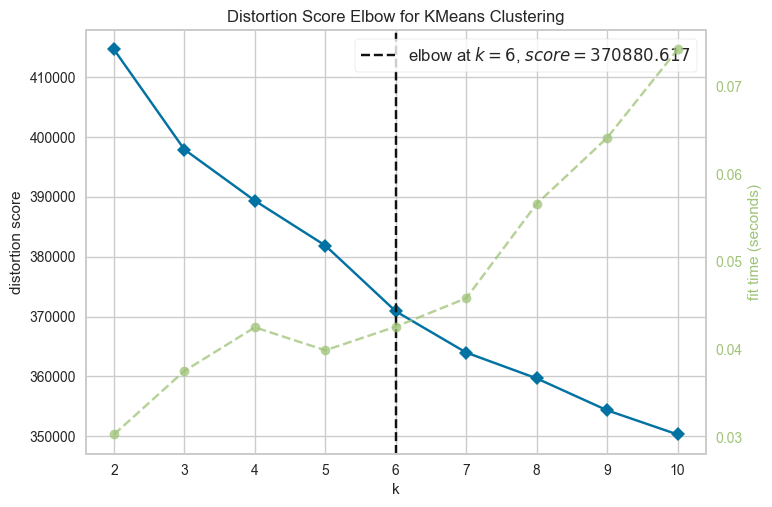

In [99]:
# clustering with elbow method to determine best num of clusters

# yellowbrick KMeans with elbow and viz
model = KElbowVisualizer(KMeans(n_init="auto"), k=10)

model.fit(go_sample)
model.show()
plt.show()

In [100]:
# find clusters

num_of_neighbors = (3, 5, 7)

for n in num_of_neighbors:
    clusterer = hdbscan.HDBSCAN(min_cluster_size=n)
    cluster_labels = clusterer.fit_predict(go_sample)

    # scoring clustering with silhouette
    scores = silhouette_score(go_sample, cluster_labels)
    print(
        f"# neighbors = {n}, # clusters = {len(np.unique(cluster_labels))} | Mean Silhouette Score = {scores:.2f}"
    )

# neighbors = 3, # clusters = 4 | Mean Silhouette Score = 0.03
# neighbors = 5, # clusters = 5 | Mean Silhouette Score = -0.05
# neighbors = 7, # clusters = 3 | Mean Silhouette Score = -0.00


In [101]:
# sklearn kmeans

num_clusters = 4

kmeans = KMeans(n_clusters=num_clusters, n_init="auto", random_state=42).fit(go_sample)

# add to tsne results
go_df_sample["kmeans_cluster"] = kmeans.labels_

# group mol_id by cluster
cluster_gols = (
    go_df_sample.groupby("kmeans_cluster")["go_id"].agg(lambda x: list(x)).sort_values()
)

# create df with clusters and number of items per cluster
cluster_gols_counts = pd.DataFrame(cluster_gols)
cluster_gols_counts.insert(0, "n_items", [len(x) for x in cluster_gols])
cluster_gols_counts.sort_values(by="n_items", ascending=False, inplace=True)
cluster_gols_counts.reset_index(drop=False, inplace=True)

# save metadata
cluster_gols_counts.to_csv(go_folder / "biobert/go_kmeans_clusters.csv", index=False)

# saving sampled dataset with clusters' ids
go_df_sample.to_csv(go_folder / "biobert/go_embeddings_kmeans.csv", index=False)

print(f"Sampled GO embeddings shape: {go_df_sample.shape}")

print(go_df_sample.value_counts(subset=["namespace"]))

cluster_gols_counts

Sampled GO embeddings shape: (4000, 772)
namespace         
biological_process    2559
molecular_function    1067
cellular_component     374
Name: count, dtype: int64


,kmeans_cluster,n_items,go_id
0,1,1203,"[GO:0070248, GO:0030838, GO:1901544, GO:004851..."
1,2,1181,"[GO:0030776, GO:0004135, GO:0046465, GO:005006..."
2,3,1082,"[GO:0035869, GO:0030135, GO:0061201, GO:003120..."
3,0,534,"[GO:1905314, GO:2000793, GO:1905222, GO:000984..."


In [107]:
# UMAP with 3 components for 3D visualization (with dimensionality reduction)

# create a dictionary to store the outputs
umap_dict = {}

# parameters
n_neighbors_list = [3, 5, 15, 30]
min_dist_list = [0.0, 0.2, 0.99]
metrics = ["cosine", "euclidean", "manhattan"]
n_epochs = [1000]
learning_rate = 1

# for progress tracking
total_iterations = (
    len(n_neighbors_list) * len(min_dist_list) * len(metrics) * len(n_epochs)
)

parameter_combinations = product(n_neighbors_list, min_dist_list, metrics, n_epochs)


for n_neighbors, min_dist, metric, epoch in tqdm(
    parameter_combinations, total=total_iterations, desc="UMAP Parameter Search"
):

    reducer = umap.UMAP(
        n_components=3,
        n_neighbors=n_neighbors,
        metric=metric,
        n_epochs=epoch,
        learning_rate=learning_rate,
        min_dist=min_dist,
        verbose=False,
        random_state=42,
    )
    results = reducer.fit_transform(go_sample)

    # store results
    umap_dict.update({f"{n_neighbors}_{min_dist}_{metric}_{epoch}": results})


# create dataframe with results for ploting
# initialize df to concatenate
df_umap = pd.DataFrame()

# iterates of tsne results and add the columns
for key, value in umap_dict.items():
    df_umap = pd.concat([df_umap, pd.DataFrame(value)], axis=1)

# create column names
coordinates = ["x", "y", "z"]
columns_names = [
    f"{coordinate}_{str(n_neighbors)}_{str(min_dist)}_{metric}_{str(epoch)}"
    for n_neighbors in n_neighbors_list
    for min_dist in min_dist_list
    for metric in metrics
    for epoch in n_epochs
    for coordinate in coordinates
]

df_umap.columns = columns_names
df_umap = pd.concat(
    [
        go_df_sample[["go_id", "namespace", "name", "kmeans_cluster"]].reset_index(
            drop=True
        ),
        df_umap,
    ],
    axis=1,
)

# save grid search
df_umap.to_csv(go_folder / "biobert/umap_grid_pca.csv", index=False)

print(df_umap.shape)
df_umap.head()

UMAP Parameter Search:   0%|          | 0/36 [00:00<?, ?it/s]

(4000, 112)


,go_id,namespace,name,kmeans_cluster,x_3_0.0_cosine_1000,y_3_0.0_cosine_1000,z_3_0.0_cosine_1000,x_3_0.0_euclidean_1000,y_3_0.0_euclidean_1000,z_3_0.0_euclidean_1000,...,z_30_0.2_manhattan_1000,x_30_0.99_cosine_1000,y_30_0.99_cosine_1000,z_30_0.99_cosine_1000,x_30_0.99_euclidean_1000,y_30_0.99_euclidean_1000,z_30_0.99_euclidean_1000,x_30_0.99_manhattan_1000,y_30_0.99_manhattan_1000,z_30_0.99_manhattan_1000
0,GO:0035869,cellular_component,ciliary transition zone,3,0.249162,1.397434,2.531622,8.712208,8.766283,3.445031,...,1.463657,4.507852,1.603011,6.665717,1.012679,4.486126,2.280012,1.257769,4.798748,3.827884
1,GO:0030776,molecular_function,"(RS)-1-benzyl-1,2,3,4-tetrahydroisoquinoline N...",2,13.902471,5.117697,5.197318,-1.800285,1.264328,0.395053,...,-1.925864,7.409761,4.171854,0.166187,7.913080,2.781855,0.084513,5.865794,6.167968,-1.600090
2,GO:0004135,molecular_function,"amylo-alpha-1,6-glucosidase activity",2,8.817570,8.517748,5.025087,1.405367,5.711408,0.379147,...,-2.937285,5.029541,8.711220,3.110701,4.936629,6.765139,-2.828239,1.234549,3.137671,-2.570457
3,GO:0030135,cellular_component,coated vesicle,3,0.480817,-1.230938,4.104818,4.191382,4.524769,-8.677958,...,0.025859,5.083256,0.970083,5.421368,3.167545,2.095571,2.691425,3.530715,6.883510,3.357589
4,GO:0070248,biological_process,negative regulation of natural killer cell apo...,1,-0.588423,4.406564,6.311830,9.302977,10.032148,-0.805156,...,3.707822,7.488232,3.893079,9.051007,2.011577,6.039272,5.258379,3.574611,2.459671,5.586811


In [117]:
# interactive plot

# Load mapping
df_map = pd.read_csv(go_folder / "biobert/umap_grid.csv")

# plot
n_neighbors = 15
min_dist = 0.0
metric = "cosine"
epochs = 1000
width = 800
height = 600
size = 2
opacity = 0.8

# namespace labels
fig = px.scatter_3d(
    df_umap,
    x=f"x_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    y=f"y_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    z=f"z_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    color=df_umap["namespace"],
    labels={"color": "namespace"},
    hover_data=["name"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()

# cluster labels
fig = px.scatter_3d(
    df_umap,
    x=f"x_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    y=f"y_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    z=f"z_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    color=df_umap["kmeans_cluster"],
    labels={"color": "cluster"},
    hover_data=["name"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()

In [102]:
# spectral embedding

# create a dictionary to store the outputs
se_dict = {}

n_neighbors = [3, 5, 10, 20, 30, 50, 100]

for n_neighbor in tqdm(
    n_neighbors, total=len(n_neighbors), desc="Searching n_neighbors..."
):

    se = SpectralEmbedding(
        n_components=3,
        n_neighbors=n_neighbor,
        affinity="rbf",
        random_state=42,
        n_jobs=-1,
    )
    results = se.fit_transform(go_sample)

    se_dict.update({n_neighbor: results})


# create dataframe with results for ploting
# initialize df to concatenate
df_se = pd.DataFrame()

# iterates of tsne results and add the columns
for key, value in se_dict.items():
    df_se = pd.concat([df_se, pd.DataFrame(value)], axis=1)

# create column names
coordinates = ["x", "y", "z"]
columns_names = [
    f"{item2}_{str(item1)}" for item1 in n_neighbors for item2 in coordinates
]

df_se.columns = columns_names

# add data to go_df_sample dataframe
df_se = pd.concat(
    [
        go_df_sample[["go_id", "name", "namespace", "kmeans_cluster"]].reset_index(
            drop=True
        ),
        df_se,
    ],
    axis=1,
)

# save grid search
df_se.to_csv(go_folder / "biobert/spectral_grid.csv", index=False)

print(df_se.shape)
df_se.head()

Searching n_neighbors...:   0%|          | 0/7 [00:00<?, ?it/s]

(4000, 25)


,go_id,name,namespace,kmeans_cluster,x_3,y_3,z_3,x_5,y_5,z_5,...,z_20,x_30,y_30,z_30,x_50,y_50,z_50,x_100,y_100,z_100
0,GO:0035869,ciliary transition zone,cellular_component,3,-0.000304,-0.000419,-0.000045,-0.000304,-0.000419,-0.000045,...,-0.000045,-0.000304,-0.000419,-0.000045,-0.000303,-0.000419,-0.000045,-0.000304,-0.000419,-0.000045
1,GO:0030776,"(RS)-1-benzyl-1,2,3,4-tetrahydroisoquinoline N...",molecular_function,2,0.000498,0.000051,0.000001,0.000498,0.000051,0.000001,...,0.000001,0.000498,0.000051,0.000001,0.000498,0.000051,0.000001,0.000498,0.000051,0.000001
2,GO:0004135,"amylo-alpha-1,6-glucosidase activity",molecular_function,2,0.000362,-0.000112,-0.000318,0.000362,-0.000112,-0.000318,...,-0.000318,0.000362,-0.000112,-0.000318,0.000362,-0.000112,-0.000318,0.000362,-0.000112,-0.000318
3,GO:0030135,coated vesicle,cellular_component,3,-0.000295,-0.000540,-0.000395,-0.000295,-0.000540,-0.000395,...,-0.000395,-0.000296,-0.000540,-0.000395,-0.000296,-0.000540,-0.000395,-0.000296,-0.000540,-0.000395
4,GO:0070248,negative regulation of natural killer cell apo...,biological_process,1,-0.000278,0.000544,-0.000581,-0.000278,0.000544,-0.000581,...,-0.000581,-0.000278,0.000544,-0.000581,-0.000279,0.000544,-0.000581,-0.000278,0.000544,-0.000581


In [108]:
# interactive plot

# Load mapping
df_se = pd.read_csv(go_folder / "biobert/spectral_grid.csv")

# plot
p = "5"  # n_neighbors

width = 800
height = 600
size = 2
opacity = 0.7

# label: aspect
fig = px.scatter_3d(
    df_se,
    x=f"x_{p}",
    y=f"y_{p}",
    z=f"z_{p}",
    color=df_se["namespace"],
    labels={"color": "namespace"},
    hover_data=["name"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()

# label: cluster
fig = px.scatter_3d(
    df_se,
    x=f"x_{p}",
    y=f"y_{p}",
    z=f"z_{p}",
    color=df_se["kmeans_cluster"],
    labels={"color": "cluster"},
    hover_data=["name"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()

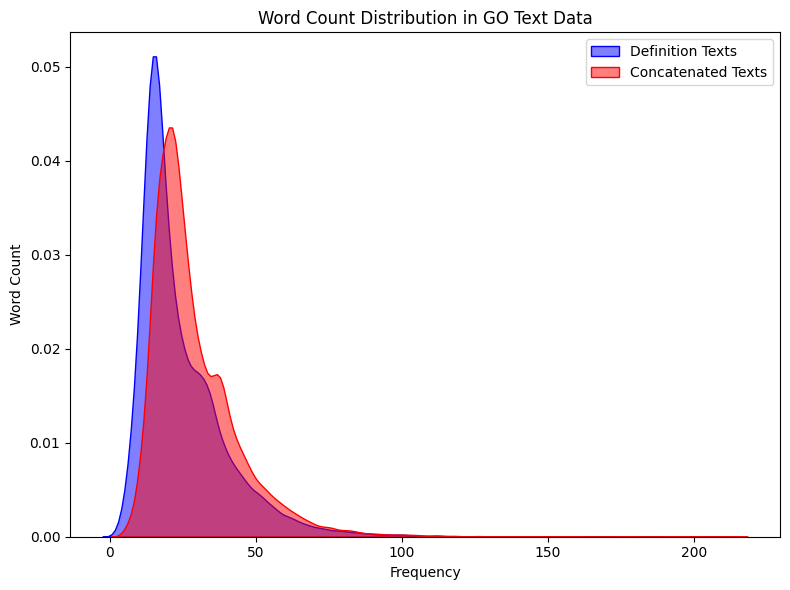

In [26]:
# Plot word count distributions

plt.figure(figsize=(8, 6))

sns.kdeplot(
    go_df["def_word_count"],
    color="blue",
    label="Definition Texts",
    fill=True,
    alpha=0.5,
)

sns.kdeplot(
    go_df["concat_text_word_count"],
    color="red",
    label="Concatenated Texts",
    fill=True,
    alpha=0.5,
)

plt.title("Word Count Distribution in GO Text Data")
plt.xlabel("Frequency")
plt.ylabel("Word Count")
plt.legend()

plt.tight_layout()
plt.savefig(go_folder / "word_counts.png", dpi=300)
plt.show()

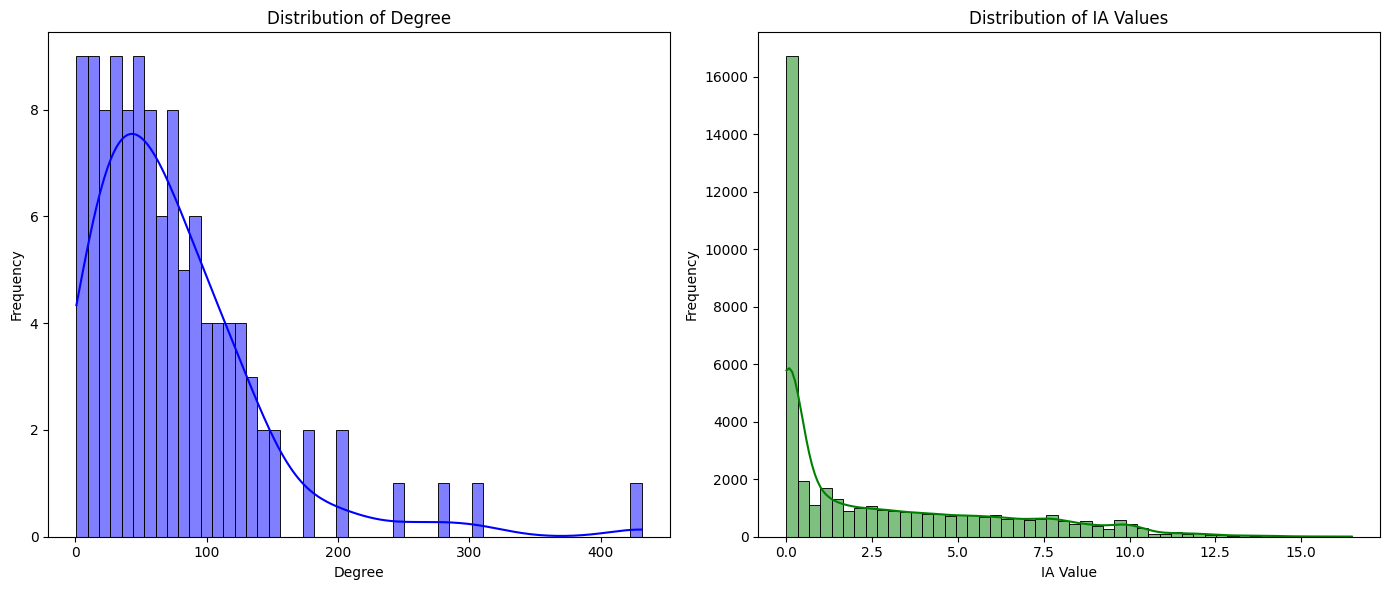

In [27]:
# Histograms for Degree and IA

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(go_df["degree"].unique(), bins=50, kde=True, ax=ax[0], color="blue")
ax[0].set_title("Distribution of Degree")
ax[0].set_xlabel("Degree")
ax[0].set_ylabel("Frequency")

sns.histplot(go_df["ia"], bins=50, kde=True, ax=ax[1], color="green")
ax[1].set_title("Distribution of IA Values")
ax[1].set_xlabel("IA Value")
ax[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig(go_folder / "degrees_ia_distribution.png", dpi=300)
plt.show()

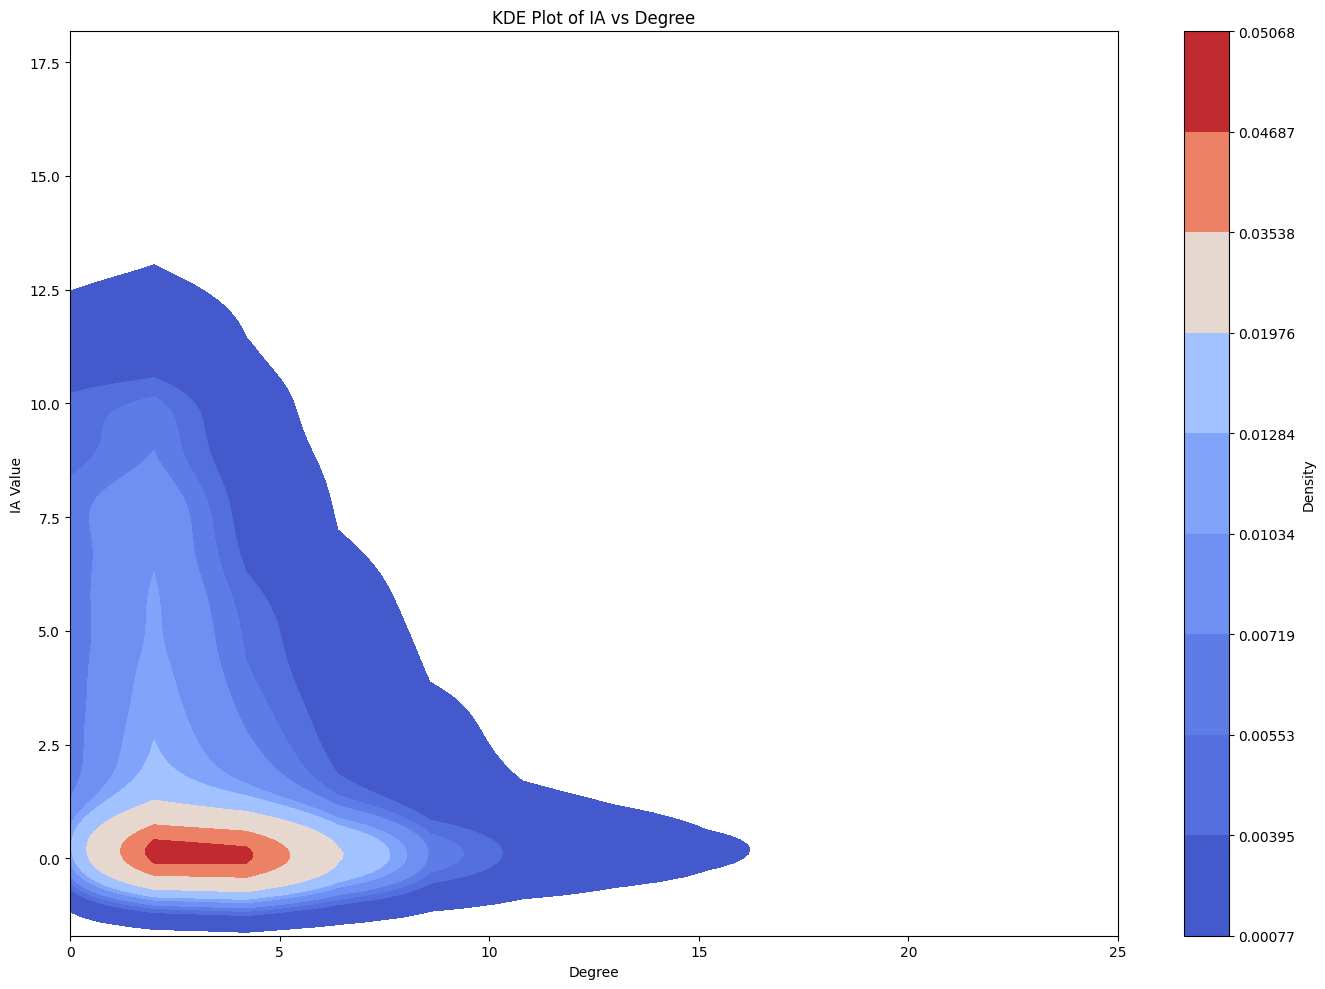

In [28]:
# KDE plot for IA vs Degree

plt.figure(figsize=(14, 10))

sns.kdeplot(
    data=go_df,
    x="degree",
    y="ia",
    cmap="coolwarm",
    fill=True,
    cbar=True,
    cbar_kws={"label": "Density"},
)
plt.xlim(0, 25)
plt.title("KDE Plot of IA vs Degree")
plt.xlabel("Degree")
plt.ylabel("IA Value")
plt.tight_layout()
plt.savefig(go_folder / "degree_vs_ia_heatmap.png", dpi=300)
plt.show()

### Build GO Graph

In [119]:
# Convert features to tensors

go_feats = torch.stack([torch.tensor(v, dtype=torch.float32) for v in go_embed_dict.values()])

# Create mapping dict
go_ids = list(go_embed_dict.keys())
go_ids_map = dict(zip(go_ids, range(len(go_ids))))
go_feats_map = dict(zip(go_ids, go_feats))


print(f"# of embeddings: {len(go_embed_dict)}")
print(f"# of unique GO terms: {len(go_ids)}")

for key, value in go_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in go_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

# of embeddings: 42093
# of unique GO terms: 42093
key: GO:0000001, value: 0
key: GO:0000001, value: torch.Size([768])


#### Define Single Edge Type

In [120]:
# Create GO graph edge_index (intra-edges)

edges_to_tensor = [
    [go_ids_map[e[0]], go_ids_map[e[1]]] for e in go_graph.edges(data=True)
]
edge_index_go = torch.tensor(edges_to_tensor, dtype=torch.long).t().contiguous()

print(f"edge_index shape: {edge_index_go.shape}")
edge_index_go

edge_index shape: torch.Size([2, 81173])


tensor([[    0,     0,     1,  ..., 42092, 42092, 42092],
        [22355, 22357,  4615,  ..., 17559, 33626, 42091]])

In [121]:
# Creates torch geometric HeteroData object and save GO graph

go_data = Data()
go_data.x = go_feats
go_data.edge_index = edge_index_go

# Save data
save_file_path = go_folder / "go_graph_dataset.pt"
torch.save(go_data, save_file_path)
go_data

Data(x=[42093, 768], edge_index=[2, 81173])

## Prepare PPI Graph

### Filter Protein-GO Associations

In [122]:
# Load protein-GO associations to filter obsolete GO terms

associations_df = pd.read_csv(data_folder / "cafa/associations.tsv", sep="\t")

# Filter out obsolete GO terms using up to date GO DAG
associations_df = associations_df[associations_df["go_id"].isin(go_ids)]

print(f"Protein-GO associations dims: {associations_df.shape}")
associations_df.head()

Protein-GO associations dims: (5085158, 3)


,uniprot_id,go_id,aspect
0,A0A009IHW8,GO:0008152,BPO
1,A0A009IHW8,GO:0034655,BPO
2,A0A009IHW8,GO:0072523,BPO
4,A0A009IHW8,GO:0006753,BPO
5,A0A009IHW8,GO:1901292,BPO


### Load (filtered) Sequences and Parse

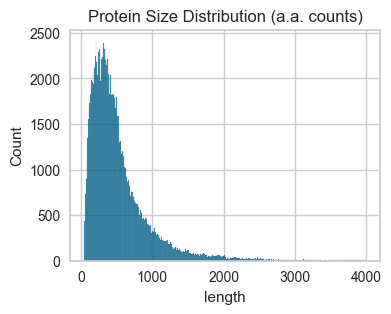

Sequences df dims: (140233, 3)
     uniprot_id                                           sequence  length
587  A0A0G2K6R9  MMNEDAAQKSDSGEKFNGSSQRRKRPKKSDSNASFLRAARAGNLDK...    3998
588  A0A2R8Q1V0  MGRFTIYRVLKKSGLSGLKVLKPQKCSFQPCSNTLTYTCQDCICYN...    3997
589      Q9Y4D8  MPANHLPIGSTMSTVHLSSDGTYFYWIWSPASLNEKTPKGHSVFMD...    3996
590  A0A5F9ZH30  MTTMLQKSDSNASFLRAARAGNLDKVVEYLKGGIDINTCNQNGLNA...    3995
591      Q80TY5  MLESYVTPILMSYVNRYIKNLKPSDLQLSLWGGDVVLSKLELKLDV...    3993


In [123]:
# Load and parse sequences from CAFA5

min_length = 50  # Minimum length threshold
max_length = 4000  # Maximum length threshold

# Load sequences and build df
file_path = data_folder / "cafa/train_sequences.fasta"
sequences = []
for record in SeqIO.parse(file_path, "fasta"):
    sequences.append(
        {
            "uniprot_id": record.id,
            "sequence": str(record.seq),
            "length": len(record.seq),
        }
    )

# Convert list of dictionaries to DataFrame
sequences_df = pd.DataFrame(sequences)
sequences_df = sequences_df.sort_values(by="length", ascending=False).reset_index(
    drop=True
)

# Filter sequences based on length
sequences_df_filtered = sequences_df[
    (sequences_df["length"] <= max_length) & (sequences_df["length"] >= min_length)
]

# Filter out proteins with obsolete GO terms (assuming go_nodes is defined)
valid_uniprot_ids = associations_df["uniprot_id"].to_numpy()  # extract ids of selected lenght range

filtered_sequences_df = sequences_df_filtered[
    sequences_df_filtered["uniprot_id"].isin(valid_uniprot_ids)
].reset_index(drop=True)

# Plot histogram of protein sizes
plt.figure(figsize=(4, 3))
sns.histplot(sequences_df_filtered, x="length", binwidth=10).set(
    title="Protein Size Distribution (a.a. counts)"
)
plt.savefig(data_folder / "cafa/cafa_protein_size_dist.png", dpi=300)
plt.show()

# Save the filtered data
sequences_df_filtered.to_csv(data_folder / "cafa/sequences.csv", index=False)

print(f"Sequences df dims: {sequences_df_filtered.shape}")
print(sequences_df_filtered.head())

### Load PPI Data (DIP)

In [124]:
# Load PPI data (DIP human) and preprocess

file_path = data_folder / f"dip/{species_folder.as_posix().split("/")[-1]}.txt"  # human PPI

ppi_df = pd.read_csv(file_path, delimiter=",", on_bad_lines="warn")

print(ppi_df.info())
ppi_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7794 entries, 0 to 7793
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   ID interactor A                  7794 non-null   object
 1   ID interactor B                  7794 non-null   object
 2   Alt. ID interactor A             7794 non-null   object
 3   Alt. ID interactor B             7794 non-null   object
 4   Alias(es) interactor A           7794 non-null   object
 5   Alias(es) interactor B           7794 non-null   object
 6   Interaction detection method(s)  7794 non-null   object
 7   Publication 1st author(s)        7794 non-null   object
 8   Publication Identifier(s)        7794 non-null   object
 9   Taxid interactor A               7794 non-null   object
 10  Taxid interactor B               7794 non-null   object
 11  Interaction type(s)              7794 non-null   object
 12  Source database(s)               7

,ID interactor A,ID interactor B,Alt. ID interactor A,Alt. ID interactor B,Alias(es) interactor A,Alias(es) interactor B,Interaction detection method(s),Publication 1st author(s),Publication Identifier(s),Taxid interactor A,Taxid interactor B,Interaction type(s),Source database(s),Interaction identifier(s),Confidence value(s),Processing Status
0,DIP-617N|refseq:NP_000607|uniprotkb:P01730,DIP-617N|refseq:NP_000607|uniprotkb:P01730,-,-,-,-,MI:0114(x-ray crystallography)|MI:0031(protein...,-,pubmed:9168119|pubmed:DIP-17838S|pubmed:916811...,taxid:9606(Homo sapiens),taxid:9606(Homo sapiens),MI:0407(direct interaction)|MI:0407(direct int...,MI:0465(dip),DIP-42E,dip-quality-status:core,dip:0004(small scale)|dip:0004(small scale)
1,DIP-493N|uniprotkb:Q62311,DIP-147N|uniprotkb:P21675,-,-,-,-,MI:0019(coimmunoprecipitation)|MI:0404(comigra...,-,pubmed:7667268|pubmed:DIP-231S|pubmed:7667268|...,taxid:10090(Mus musculus),taxid:9606(Homo sapiens),MI:0218(physical interaction)|MI:0218(physical...,MI:0465(dip),DIP-172E,dip-quality-status:core,dip:0002(small scale)|dip:0002(small scale)|di...
2,DIP-472N|refseq:NP_005047|uniprotkb:P29375,DIP-582N|refseq:NP_000312|uniprotkb:P06400,-,-,-,-,MI:0401(biochemical)|MI:0006(anti bait coimmun...,-,pubmed:8414517|pubmed:DIP-109S|pubmed:22615382...,taxid:9606(Homo sapiens),taxid:9606(Homo sapiens),MI:0218(physical interaction)|MI:0915(physical...,MI:0465(dip),DIP-214E,dip-quality-status:core,dip:0002(small scale)|dip:0004(small scale)|di...
3,DIP-1078N|refseq:NP_003185|uniprotkb:P20226,DIP-51N|uniprotkb:P09086,-,-,-,-,MI:0019(coimmunoprecipitation)|MI:0401(biochem...,-,pubmed:8202368|pubmed:DIP-468S|pubmed:8202368|...,taxid:9606(Homo sapiens),taxid:9606(Homo sapiens),MI:0218(physical interaction)|MI:0218(physical...,MI:0465(dip),DIP-320E,dip-quality-status:core,dip:0002(small scale)|dip:0002(small scale)
4,DIP-189N|refseq:NP_005179|uniprotkb:P22681,DIP-199N|refseq:refseq|uniprotkb:P46108,-,-,-,-,MI:0045(experimental interaction detection),-,pubmed:9178909|pubmed:DIP-185S,taxid:9606(Homo sapiens),taxid:9606(Homo sapiens),MI:0218(physical interaction),MI:0465(dip),DIP-401E,dip-quality-status:core,dip:0002(small scale)


In [125]:
# Preprocess dataset

# Keep only relevant columns
ppi_df.drop(
    columns=[
        "Alt. ID interactor A",
        "Alt. ID interactor B",
        "Alias(es) interactor A",
        "Alias(es) interactor B",
        "Publication 1st author(s)",
        "Publication Identifier(s)",
        "Source database(s)",
        "Interaction identifier(s)",
        "Processing Status",
    ],
    inplace=True,
)


# Rename remaining columns
new_column_names = {
    "ID interactor A": "uniprot_id_A",
    "ID interactor B": "uniprot_id_B",
    "Interaction detection method(s)": "detection_method",
    "Taxid interactor A": "taxiID_A",
    "Taxid interactor B": "taxiID_B",
    "Interaction type(s)": "ppi_type",
    "Confidence value(s)": "confidence",
}

ppi_df.rename(columns=new_column_names, inplace=True)

# Reorder columns
ppi_df = ppi_df[
    [
        "uniprot_id_A",
        "uniprot_id_B",
        "ppi_type",
        "detection_method",
        "confidence",
        "taxiID_A",
        "taxiID_B",\
    ]
]

# Format data

# Extract uniprot ids
ppi_df["uniprot_id_A"] = ppi_df["uniprot_id_A"].apply(extract_uniprot_ids)
ppi_df["uniprot_id_B"] = ppi_df["uniprot_id_B"].apply(extract_uniprot_ids)

# Extract methods
ppi_df["detection_method"] = ppi_df["detection_method"].apply(extract_methods)

# Extract taxIDs
ppi_df["taxiID_A"] = ppi_df["taxiID_A"].apply(extract_taxiIDs)
ppi_df["taxiID_B"] = ppi_df["taxiID_B"].apply(extract_taxiIDs)

# Extract PPI type
ppi_df["ppi_type"] = ppi_df["ppi_type"].apply(extract_ppi_type)

# Extract confidence score
ppi_df["confidence"] = ppi_df["confidence"].apply(extract_confidence_score)

# Remove PPI pairs of diferent organisms
ppi_df = ppi_df[ppi_df["taxiID_A"] == ppi_df["taxiID_B"]]
ppi_df.reset_index(drop=True, inplace=True)

# Filter out PPI pairs without associations (protein-GO)
unique_associations_protein_ids = associations_df["uniprot_id"].unique()
ppi_df = ppi_df[
    (ppi_df["uniprot_id_A"].isin(unique_associations_protein_ids))
    & (ppi_df["uniprot_id_B"].isin(unique_associations_protein_ids))
]

# Remove self-loops (A = B)
ppi_df = ppi_df[(ppi_df["uniprot_id_A"] != ppi_df["uniprot_id_B"])]

# Remove proteins without embeddings (large proteins)
unique_sequences_protein_ids = sequences_df["uniprot_id"].unique()
ppi_df = ppi_df[
    (ppi_df["uniprot_id_A"].isin(unique_sequences_protein_ids))
    & (ppi_df["uniprot_id_B"].isin(unique_sequences_protein_ids))
]

# Handling NA values in uniprot IDs
# There are entries without reference to Uniprot IDs
print(
    "# of missing UniProt IDs (A, B):",
    (
        len(ppi_df[ppi_df["uniprot_id_A"].isna()]),
        len(ppi_df[ppi_df["uniprot_id_B"].isna()]),
    ),
)

# Drop NAs
ppi_df.dropna(inplace=True)

# Reset index and save processed df
ppi_df.reset_index(drop=True, inplace=True)
ppi_df.to_csv(species_folder / "datasets/ppi.csv", index=False)

print(f"PPI df shape: {ppi_df.shape}")
print(ppi_df.head().to_markdown())
ppi_df.describe()

# of missing UniProt IDs (A, B): (0, 0)
PPI df shape: (4683, 7)
|    | uniprot_id_A   | uniprot_id_B   | ppi_type                                  | detection_method                                                            | confidence   |   taxiID_A |   taxiID_B |
|---:|:---------------|:---------------|:------------------------------------------|:----------------------------------------------------------------------------|:-------------|-----------:|-----------:|
|  0 | P29375         | P06400         | physical interaction;physical association | biochemical;anti bait coimmunoprecipitation;anti bait coimmunoprecipitation | core         |       9606 |       9606 |
|  1 | P20226         | P09086         | physical interaction                      | coimmunoprecipitation;biochemical                                           | core         |       9606 |       9606 |
|  2 | P22681         | P46108         | physical interaction                      | experimental interaction detection 

,uniprot_id_A,uniprot_id_B,ppi_type,detection_method,confidence,taxiID_A,taxiID_B
count,4683,4683,4683,4683,4683,4683,4683
unique,2144,2105,53,1075,2,1,1
top,P04637,P04637,physical association,anti tag coimmunoprecipitation,core,9606,9606
freq,29,37,2705,622,4536,4683,4683


### Extract Metadata

In [126]:
# Obtain PPI metadata

# Check PPI types in the dataset
# Get unique lists of ppi types
ppi_types = ppi_df["ppi_type"].unique()

# Get unique PPI types from lists of PPI types
unique_ppi_types = set(
    ppi_type.strip() for sublist in ppi_types for ppi_type in sublist.split(";")
)
unique_ppi_types = sorted(unique_ppi_types)  # convert to list

# Save list
file_path = species_folder / "metadata/ppi_types.txt"
with open(file_path, "w") as f:
    f.write(str(unique_ppi_types))

# Check PPI detection methods in the dataset
# Get unique lists of detection methods
methods = ppi_df["detection_method"].unique()

# Get unique PPI types from lists of PPI types
unique_methods = set(
    method.strip() for sublist in methods for method in sublist.split(";")
)
unique_methods = sorted(unique_methods)  # convert to list

# Save list
file_path = species_folder / "metadata/ppi_methods.txt"
with open(file_path, "w") as f:
    f.write(str(unique_methods))

print(f"# of unique PPI detection methods: {len(unique_methods)}")
print(unique_methods[:5])
print(f"# of unique PPI types: {len(unique_ppi_types)}")
print(unique_ppi_types)

# of unique PPI detection methods: 85
['Split renilla luciferase complementation', 'acetylation assay', 'adp ribosylase assay', 'affinity chromatography technology', 'amplified luminescent proximity homogeneous assay']
# of unique PPI types: 20
['acetylation reaction', 'adp ribosylation reaction', 'ampylation reaction', 'association', 'cleavage reaction', 'covalent binding', 'deacetylation reaction', 'demethylation reaction', 'dephosphorylation reaction', 'deubiquitination reaction', 'direct interaction', 'disulfide bond', 'genetic interference', 'hydroxylation reaction', 'methylation reaction', 'oxidoreductase activity electron transfer assay', 'phosphorylation reaction', 'physical association', 'physical interaction', 'protein cleavage']


In [127]:
# PPI counts (unique)

# Extract interactions
ppi_pairs = list(
    tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy()
)

# Extract unique interactions
ppi_unique_pairs = list(
    set(tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy())
)

# Extract unique uniprot ids in interactions
ppi_unique_ids = pd.concat([ppi_df["uniprot_id_A"], ppi_df["uniprot_id_B"]]).unique()

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of PPIs: {len(ppi_pairs)}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

# of unique UniProt IDs: 2955
# of PPIs: 4683
# of unique PPIs: 4666


### Build NetworkX Graph to Extract LCC

In [128]:
# Construct nx graph to extract LCC

# Create undirected graph instance
ppi_graph = nx.Graph()

# Add edges
ppi_graph.add_edges_from(ppi_unique_pairs)

# Get connected components and lcc
cc = list(nx.connected_components(ppi_graph))
lcc = max(cc, key=len)

# Extract subgraph with lcc
ppi_graph_lcc = ppi_graph.subgraph(lcc).copy()

# Extract nodes and edges for graph dataset
ppi_nodes = ppi_graph_lcc.nodes()
ppi_edges = list(ppi_graph_lcc.edges())

# print-out basic graph attributes
print(f"# of nodes: {ppi_graph.number_of_nodes()}")
print(f"# of edges: {ppi_graph.number_of_edges()}")
print(f"Is connected?: {nx.is_connected(ppi_graph_lcc)}")
print(f"\n# of connected components: {len(cc)}")
print(f"\n# of nodes (LCC): {len(ppi_nodes)}")
print(f"# of edges (LCC): {len(ppi_edges)}")
print(f"Is connected? (LCC): {nx.is_connected(ppi_graph_lcc)}")

# of nodes: 2955
# of edges: 4666
Is connected?: True

# of connected components: 198

# of nodes (LCC): 2366
# of edges (LCC): 4209
Is connected? (LCC): True


In [129]:
# PPI counts

# Extract unique interactions
ppi_unique_pairs = list(
    set(tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy())
)
# Extract unique uniprot ids in interactions
ppi_unique_ids = pd.concat([ppi_df["uniprot_id_A"], ppi_df["uniprot_id_B"]]).unique()

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

# of unique UniProt IDs: 2955
# of unique PPIs: 4666


In [130]:
# Filter protein-go associations with LCC nodes

# Keep full protein-GO associations for plotting
associations_full = associations_df.copy()

# Remove associations with large proteins
associations_df = associations_df[
    associations_df["uniprot_id"].isin(list(ppi_graph_lcc.nodes()))
].copy()

associations_df = associations_df[
    associations_df["uniprot_id"].isin(sequences_df_filtered["uniprot_id"].unique())
]
associations_df.reset_index(drop=True, inplace=True)

# Save filtered df
file_path = species_folder / "datasets/associations.tsv"
associations_df.to_csv(file_path, sep="\t", index=False)


print(f"Filtered Protein-GO associations dims: {associations_df.shape}")
print(f"# of unique UniProt IDs: {len(associations_df['uniprot_id'].unique())}")
associations_df.head()

Filtered Protein-GO associations dims: (239395, 3)
# of unique UniProt IDs: 2352


,uniprot_id,go_id,aspect
0,A1YPR0,GO:0050789,BPO
1,A1YPR0,GO:0048523,BPO
2,A1YPR0,GO:0048519,BPO
3,A1YPR0,GO:0065007,BPO
4,A1YPR0,GO:0008285,BPO


### Build PPI Graph

In [131]:
# Load embeddings

emb_dataset = ProteinEmbeddingDataset(data_folder / "cafa/protein_embeddings")

print(f"# of protein embeddings: {len(emb_dataset)}")

# of protein embeddings: 140233


In [ ]:
# Collect uniprot ids and embeddings from Dataloader

# iterates over dataset in batches to extract sequences and ids
protein_embed_dict = {}
unique_proteins_lcc_cafa = associations_df["uniprot_id"].unique()

loader = DataLoader(emb_dataset, batch_size=1, shuffle=False)
for batch in tqdm(loader, total=len(loader), desc="Loading Protein Dataset..."):
    uniprot_id = str(batch["uniprot_id"][0])
    if batch["uniprot_id"][0] in unique_proteins_lcc_cafa:
        protein_embed_dict[batch["uniprot_id"][0]] = batch["tensor"].numpy().flatten()

# Save protein embeddings dict
save_file_path = species_folder / "datasets/protein_embeddings.pkl"
with open(save_file_path, "wb") as file:
    pickle.dump(protein_embed_dict, file)

# Convert embeddings to tensors
protein_feats = torch.stack(
    [torch.tensor(v, dtype=torch.float32) for v in protein_embed_dict.values()]
)

# Create mapping dict
protein_ids = list(protein_embed_dict.keys())
protein_ids_map = dict(zip(protein_ids, range(len(ppi_nodes))))
protein_feats_map = dict(zip(protein_ids, protein_feats))

print(f"# of protein ids: {len(protein_ids)}")
print(f"protein feats shape: {protein_feats.shape}")

for key, value in protein_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in protein_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

In [132]:
# Load protein embeddings dict

# Get unique protein ids
unique_proteins_lcc_cafa = associations_df["uniprot_id"].unique()

# Load embeddings dict
save_file_path = species_folder / "datasets/protein_embeddings.pkl"
with open(save_file_path, "rb") as file:
    protein_embed_dict = pickle.load(file)

# Convert embeddings to tensors
protein_feats = torch.stack(
    [torch.tensor(v, dtype=torch.float32) for v in protein_embed_dict.values()]
)

# Create mapping dict
protein_ids = list(protein_embed_dict.keys())
protein_ids_map = dict(zip(protein_ids, range(len(ppi_nodes))))
protein_feats_map = dict(zip(protein_ids, protein_feats))

print(f"# of protein ids: {len(protein_ids)}")
print(f"protein feats shape: {protein_feats.shape}")

for key, value in protein_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in protein_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

# of protein ids: 2352
protein feats shape: torch.Size([2352, 1024])
key: Q71DI3, value: 0
key: Q71DI3, value: torch.Size([1024])


In [133]:
# Creates edge_index

# Extracts PPI pairs for edge construction

# Ensures that every pair of nodes intersect PPI / CAFA5
edges_to_tensor = [
    [protein_ids_map[e[0]], protein_ids_map[e[1]]]
    for e in ppi_edges
    if e[0] in unique_proteins_lcc_cafa and e[1] in unique_proteins_lcc_cafa
]

edge_index_ppi = torch.tensor(edges_to_tensor, dtype=torch.long).t().contiguous()

print(f"edge_index shape: {edge_index_ppi.shape}")
edge_index_ppi

edge_index shape: torch.Size([2, 4175])


tensor([[2201, 1756, 1756,  ..., 1396, 1784,  688],
        [1756, 2198, 1042,  ...,  686, 1852,  849]])

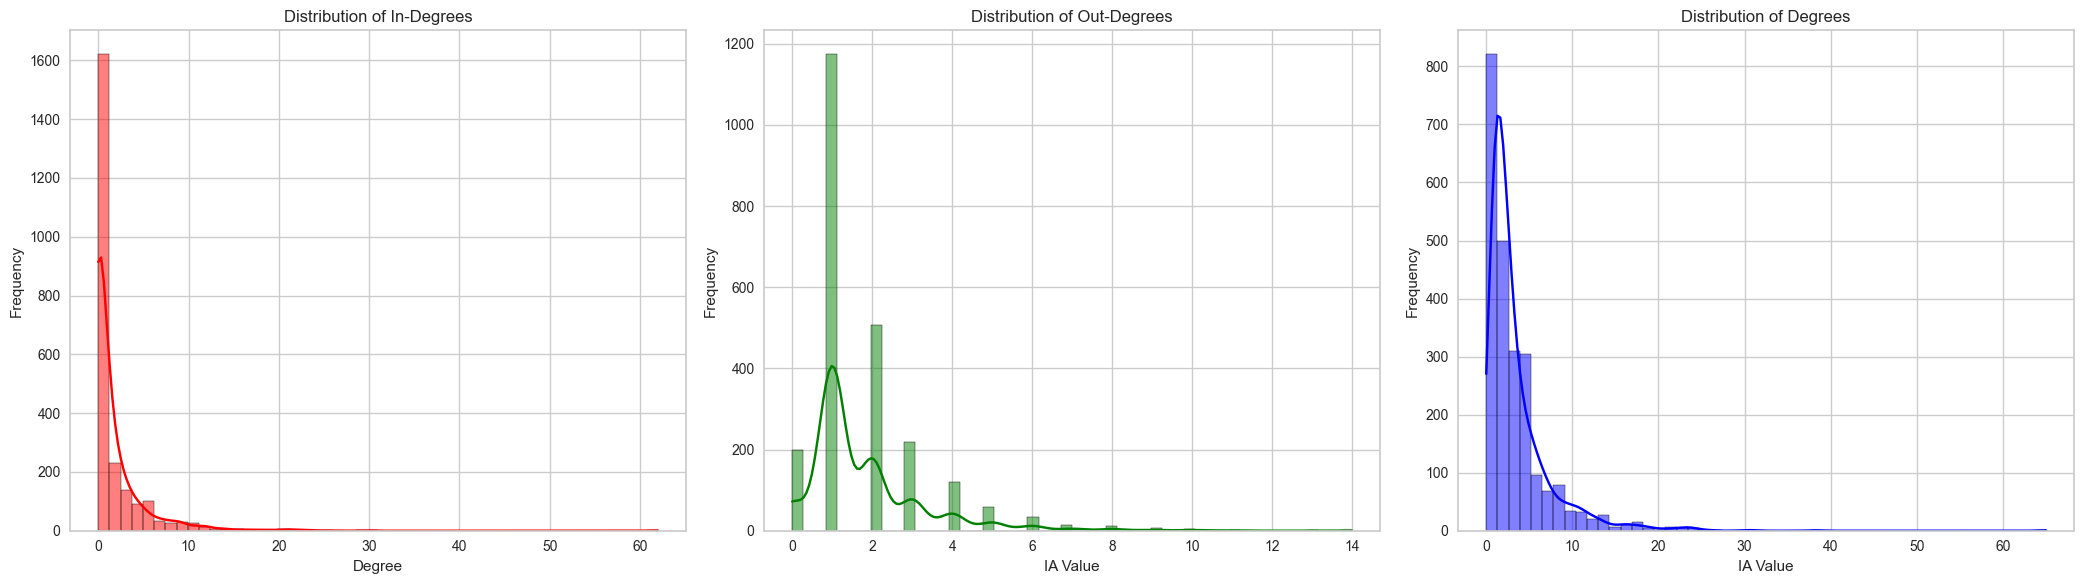

In [134]:
# Convert PPI graph to undirected

# Convert to undirected (A-B = B-A for PPI)
# Obtain degrees from ppi graph
src_degrees = degree(edge_index_ppi[0])
dst_degrees = degree(edge_index_ppi[1])

# Convert to undirected (A-B = B-A for PPI)
edge_index_ppi = to_undirected(edge_index_ppi)
degrees = degree(edge_index_ppi[0])

# Plot degree histogram
fig, ax = plt.subplots(1, 3, figsize=(21, 6))

sns.histplot(src_degrees, bins=50, kde=True, ax=ax[0], color="red")
ax[0].set_title("Distribution of In-Degrees")
ax[0].set_xlabel("Degree")
ax[0].set_ylabel("Frequency")

sns.histplot(dst_degrees, bins=50, kde=True, ax=ax[1], color="green")
ax[1].set_title("Distribution of Out-Degrees")
ax[1].set_xlabel("IA Value")
ax[1].set_ylabel("Frequency")

sns.histplot(degrees, bins=50, kde=True, ax=ax[2], color="blue")
ax[2].set_title("Distribution of Degrees")
ax[2].set_xlabel("IA Value")
ax[2].set_ylabel("Frequency")


plt.tight_layout()
plt.show()

In [135]:
# Creates torch geometric Data object and save

ppi_data = Data()
ppi_data.x = protein_feats
ppi_data.edge_index = edge_index_ppi

# Save data object
save_file_path = species_folder / "datasets/ppi_dataset.pt"
torch.save(ppi_data, save_file_path)
ppi_data

Data(x=[2352, 1024], edge_index=[2, 8350])

## Prepare PPI-GO Heterograph

#### Mapping Protein and GO ids to Unique Integer Indices

In [136]:
# Map GO terms and Uniprot IDs to respective indexes

# Map go ids
associations_df["go_idx"] = associations_df["go_id"].map(go_ids_map)

# Map proteins ids
associations_df["uniprot_idx"] = associations_df["uniprot_id"].map(protein_ids_map)

# Save
associations_df.to_csv(species_folder / "datasets/associations_indices.csv", index=False)

associations_df

,uniprot_id,go_id,aspect,go_idx,uniprot_idx
0,A1YPR0,GO:0050789,BPO,23621,399
1,A1YPR0,GO:0048523,BPO,22532,399
2,A1YPR0,GO:0048519,BPO,22528,399
3,A1YPR0,GO:0065007,BPO,27097,399
4,A1YPR0,GO:0008285,BPO,5292,399
...,...,...,...,...,...
239390,Q9Y6X2,GO:0016740,MFO,8964,171
239391,Q9Y6X2,GO:0003674,MFO,2365,171
239392,Q9Y6X2,GO:0140096,MFO,33786,171
239393,Q9Y6X2,GO:0005515,MFO,3532,171


#### Creating Protein-GO Positive Edges Index

In [137]:
# Create inter graph edges (UniProt -> GO)

edge_index_protgo_positive = torch.tensor(
    [
        associations_df["uniprot_idx"].values,
        associations_df["go_idx"].values,
    ],
    dtype=torch.long,
)

print(
    f"Protein associates with GO edge index shape: {edge_index_protgo_positive.shape}"
)
edge_index_protgo_positive

Protein associates with GO edge index shape: torch.Size([2, 239395])


tensor([[  399,   399,   399,  ...,   171,   171,   171],
        [23621, 22532, 22528,  ..., 33786,  3532, 10680]])

Negative edges generation is feasible.
Generating 478790 negative edges...
Protein negative associates with GO edge index shape: torch.Size([2, 478790])


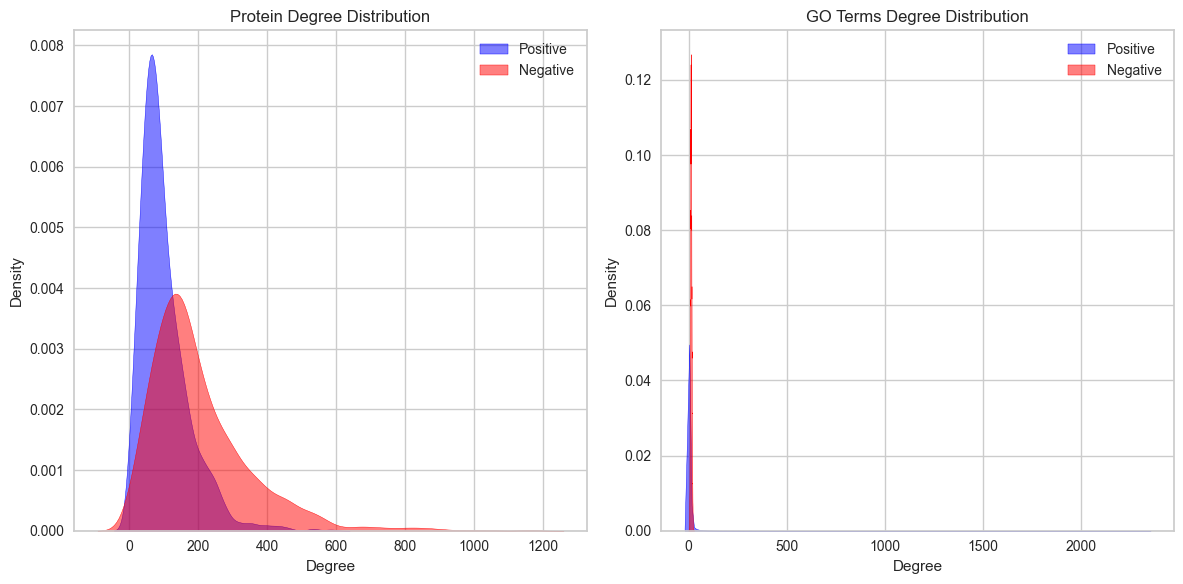

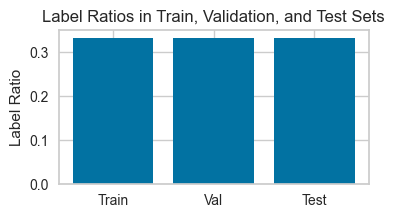

Labels (ratio): train (0.33), val (0.33), test (0.33)
HeteroData(
  protein={
    x=[2352, 1024],
    id=[2352],
  },
  go={
    x=[42093, 768],
    id=[42093],
  },
  (protein, ppi, protein)={ edge_index=[2, 8350] },
  (go, relation, go)={ edge_index=[2, 81173] },
  (protein, associates_with, go)={
    edge_index=[2, 718185],
    edge_label=[718185],
    train_mask=[718185],
    val_mask=[718185],
    test_mask=[718185],
  }
)

PPI graph directed?: False


In [138]:
# Create negative edges

# Instantiate ProteinGO dataset class
protgo_dataset = ProteinGoDataloader(
    protein_ids_map=protein_ids_map,
    go_ids_map=go_ids_map,
    species_folder=species_folder,
)

# generate hetero dataset
protgo_dataset.process(
    edge_index_protgo_positive=edge_index_protgo_positive,
    protein_feats=protein_feats,
    go_feats=go_feats,
    protein_ids=protein_ids,
    go_ids=go_ids,
    edge_index_ppi=edge_index_ppi,
    edge_index_go=edge_index_go,
    train_ratio=0.6,
    ratio=2,
)

# Check PPI graph directed
print()
print(f"PPI graph directed?: {protgo_dataset.hetero_data["protein", "ppi", "protein"].is_directed()}")

## Training

#### Barebone

In [167]:
# Custom LazyGATConv with lazy initialization

class LazyGATConv(torch.nn.Module):
    def __init__(self, out_channels, heads=1, concat=True, dropout=0.0, **kwargs):
        super(LazyGATConv, self).__init__()
        self.out_channels = out_channels
        self.heads = heads
        self.concat = concat
        self.dropout = dropout
        self.kwargs = kwargs
        self.conv = None

    def forward(self, x, edge_index, return_attention_weights=False):
        if self.conv is None:
            in_channels = x.size(-1)
            self.conv = GATConv(
                in_channels,
                self.out_channels,
                heads=self.heads,
                concat=self.concat,
                dropout=self.dropout,
                **self.kwargs,
            )
        result = self.conv(
            x, edge_index, return_attention_weights=return_attention_weights
        )
        if return_attention_weights:
            return result[0], result[1]
        else:
            return result


# HGNNGAT model
class HGNNGAT(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
    ):
        super(HGNNGAT, self).__init__()
        per_head_features = out_features // heads if concat else out_features

        self.conv1_protein = LazyGATConv(
            per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv1_go = LazyGATConv(
            per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_protein = LazyGATConv(
            per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_go = LazyGATConv(
            per_head_features, heads=heads, concat=concat, dropout=dropout
        )

        final_out_features = out_features if concat else per_head_features

        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        x_protein = self.conv1_protein(
            x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
        )
        if isinstance(x_protein, tuple):
            x_protein = x_protein[0]
        x_protein = F.elu(x_protein)

        x_go = self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        if isinstance(x_go, tuple):
            x_go = x_go[0]
        x_go = F.elu(x_go)

        x_protein = self.conv2_protein(
            x_protein, edge_index_dict[("protein", "ppi", "protein")]
        )
        if isinstance(x_protein, tuple):
            x_protein = x_protein[0]
        x_protein = F.elu(x_protein)

        x_go = self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")])
        if isinstance(x_go, tuple):
            x_go = x_go[0]
        x_go = F.elu(x_go)

        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]

        association_features = torch.cat([protein_features, go_features], dim=1)

        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores


# Evaluation function
def evaluate(model, data, criterion, mask):
    model.eval()
    with torch.no_grad():
        output = model(data.x_dict, data.edge_index_dict, mask=mask)
        loss = criterion(
            output, data["protein", "associates_with", "go"].edge_label[mask].float()
        )
        auroc = roc_auc_score(
            data["protein", "associates_with", "go"].edge_label[mask].cpu().numpy(),
            output.cpu().numpy(),
        )
    return loss.item(), auroc

In [168]:
# Training function

# Capture dict of hyperparameters
config = {
    "lr": 0.01,
    "epochs": 100,
    "batch_size": 100000,
    "dropout_rate": 0.5,
    "heads": 8,
    "out_features": 128,
}

# Initialize run
run = wandb.init(
    project="prot2go",
    notes="Barebones GAT Model",
    tags=[
        "barebones",
        "human",
        "balance 1:2",
        "go text concat",
        "biobert",
    ],
    config=config,
    # mode="disabled",
)

def train(model, data, optimizer, criterion, epochs):
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        train_mask = data["protein", "associates_with", "go"].train_mask
        output = model(data.x_dict, data.edge_index_dict, mask=train_mask)
        loss = criterion(
            output,
            data["protein", "associates_with", "go"].edge_label[train_mask].float(),
        )
        loss.backward()
        optimizer.step()

        train_auroc = roc_auc_score(
            data["protein", "associates_with", "go"]
            .edge_label[train_mask]
            .cpu()
            .numpy(),
            output.detach().numpy(),
        )

        val_loss, val_auroc = evaluate(
            model,
            data,
            criterion,
            mask=data["protein", "associates_with", "go"].val_mask,
        )

        print(
            f"Epoch {epoch + 1}/{epochs}, Train Loss: {loss.item()}, Train AUROC: {train_auroc}, Val Loss: {val_loss}, Val AUROC: {val_auroc}"
        )

        wandb.log(
            {
                "epoch": epoch + 1,
                "train_loss": loss.item(),
                "train_auroc": train_auroc,
                "val_loss": val_loss,
                "val_auroc": val_auroc,
            }
        )


# Create and train the model
model = HGNNGAT(
    protein_features=1024,
    go_features=768,
    out_features=config["out_features"],
    dropout=config["dropout_rate"],
    heads=config["heads"],
)
wandb.watch(model, log="all", log_freq=10)

optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])
criterion = torch.nn.BCEWithLogitsLoss()

# Assuming you have a dataset with the appropriate format
epochs = config["epochs"]
train(model, protgo_dataset.hetero_data.to("cpu"), optimizer, criterion, epochs)

# Evaluate on validation set
val_loss, val_auroc = evaluate(
    model,
    protgo_dataset.hetero_data.to("cpu"),
    criterion,
    mask=protgo_dataset.hetero_data["protein", "associates_with", "go"].val_mask,
)
print(f"Validation Loss: {val_loss}, Validation AUROC: {val_auroc}")

# Evaluate on test set
test_loss, test_auroc = evaluate(
    model,
    protgo_dataset.hetero_data.to("cpu"),
    criterion,
    mask=protgo_dataset.hetero_data["protein", "associates_with", "go"].test_mask,
)
print(f"Test Loss: {test_loss}, Test AUROC: {test_auroc}")

wandb.finish()

# Save Model
save_path = species_folder / "models/barebones_cpu_out_128"
save_path.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), save_path / "final_model_weights.pt")

Epoch 1/100, Train Loss: 0.6933026313781738, Train AUROC: 0.6068926357696212, Val Loss: 0.6567500829696655, Val AUROC: 0.6358619175774712
Epoch 2/100, Train Loss: 0.6487717032432556, Train AUROC: 0.6224921612760494, Val Loss: 0.6328351497650146, Val AUROC: 0.6485528887660461
Epoch 3/100, Train Loss: 0.6219022870063782, Train AUROC: 0.637073287459061, Val Loss: 0.6199223399162292, Val AUROC: 0.6637613826743339
Epoch 4/100, Train Loss: 0.6067087650299072, Train AUROC: 0.6622181436606389, Val Loss: 0.6117730736732483, Val AUROC: 0.6792068632842538
Epoch 5/100, Train Loss: 0.5979072451591492, Train AUROC: 0.6843250674908128, Val Loss: 0.604777455329895, Val AUROC: 0.6930376872573865
Epoch 6/100, Train Loss: 0.5852704048156738, Train AUROC: 0.7223001202723924, Val Loss: 0.5980173349380493, Val AUROC: 0.7036361948598693
Epoch 7/100, Train Loss: 0.5733019709587097, Train AUROC: 0.7509826246776559, Val Loss: 0.5919674634933472, Val AUROC: 0.7116476058072414
Epoch 8/100, Train Loss: 0.561378419

epoch,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
train_auroc,▁▂▄▅▆▆▆▇▇▇▇▇▇▇▇▇████████████████████████
train_loss,█▆▆▅▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_auroc,▁▂▃▄▄▄▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇██████████████████
val_loss,█▅▃▃▃▄▄▃▂▁▁▂▃▃▂▁▁▁▂▃▃▂▂▁▂▂▃▂▂▂▂▂▂▂▂▂▂▂▂▂
epoch,100
train_auroc,0.89717
train_loss,0.3906
val_auroc,0.84468
val_loss,0.58277


AUROC test: 0.84

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.55      0.69     98956
           1       0.51      0.92      0.65     49514

    accuracy                           0.68    148470
   macro avg       0.72      0.74      0.67    148470
weighted avg       0.79      0.68      0.68    148470



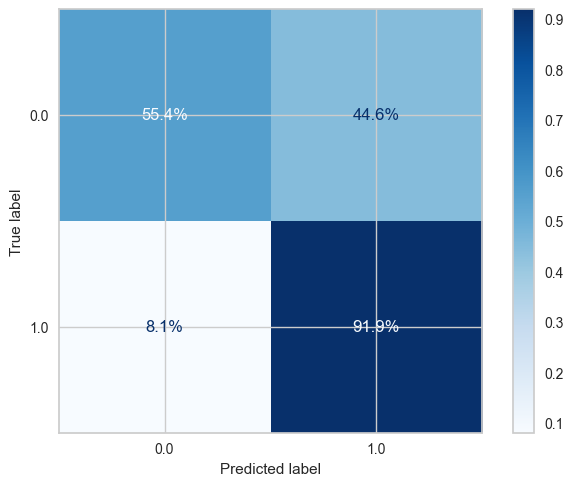

,Protein ID,GO ID,Ground Truth Label,Predicted Label,Probability
0,A2RRP1,GO:0008152,1.0,0.0,0.494131
1,A2RRP1,GO:0034655,1.0,1.0,0.594516
2,A2RRP1,GO:1902373,1.0,1.0,0.758365
3,A2RRP1,GO:0051179,1.0,1.0,0.794294
4,A2RRP1,GO:0016070,1.0,1.0,0.739207
...,...,...,...,...,...
148465,Q15054,GO:0097525,0.0,1.0,0.841074
148466,Q8IX07,GO:0062207,0.0,1.0,0.552216
148467,Q5VWQ8,GO:0070982,0.0,0.0,0.168122
148468,Q16620,GO:0043699,0.0,0.0,0.317804


In [171]:
# Evaluate test set

test_results = evaluate_model_performance(
    model,
    protgo_dataset.hetero_data.to("cpu"),
    associations_df,
    go_ids_map,
    save_path,
    "cpu",
)

test_results

### GAT Model

In [139]:
# Model Class

class HGNNGAT(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
    ):
        super(HGNNGAT, self).__init__()
        # Calculate the number of output features per head
        per_head_features = out_features // heads if concat else out_features

        # Initialize GAT layers for each type of connection with multi-head attention
        self.conv1_protein = GATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
        )
        self.conv1_go = GATConv(
            go_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_protein = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_go = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )

        # Adjust the output feature size based on concatenation or averaging of heads
        final_out_features = out_features if concat else per_head_features

        # Linear layers for making predictions
        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        # Apply the first convolution layer to protein and GO nodes
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )

        # Apply the second convolution layer
        x_protein = F.elu(
            self.conv2_protein(
                x_protein, edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))

        # Handling edges based on the mask
        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]

        # Concatenate features from proteins and GOs
        association_features = torch.cat([protein_features, go_features], dim=1)

        # Predict association
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores

    def get_attention_weights(self, x_dict, edge_index_dict):
        self.eval()
        with torch.no_grad():
            # Get attention weights from the first GAT layer for protein nodes
            x_protein, (edge_index_protein_1, attn_weights_protein_1) = (
                self.conv1_protein(
                    x_dict["protein"],
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            # Get attention weights from the second GAT layer for protein nodes
            x_protein, (edge_index_protein_2, attn_weights_protein_2) = (
                self.conv2_protein(
                    x_protein,
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )

            # Get attention weights from the first GAT layer for GO nodes
            x_go, (edge_index_go_1, attn_weights_go_1) = self.conv1_go(
                x_dict["go"],
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )
            # Get attention weights from the second GAT layer for GO nodes
            x_go, (edge_index_go_2, attn_weights_go_2) = self.conv2_go(
                x_go,
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            # Return all attention weights
            return (
                (edge_index_protein_1, attn_weights_protein_1),
                (edge_index_go_1, attn_weights_go_1),
                (edge_index_protein_2, attn_weights_protein_2),
                (edge_index_go_2, attn_weights_go_2),
            )


In [141]:
# Training and loggint to W&B

# Clean CUDA
torch.cuda.empty_cache()

# Capture dict of hyperparameters
config = {
    "lr": 0.0001,
    "epochs": 200,
    "batch_size": 100000,
    "dropout_rate": 0.5,
    "heads": 8,
    "out_features": 64,
    "weight_decay": 1e-6,
    "scheduler_patience": 10,
    "early_stopping_patience": 10,
}


# Initialize run
run = wandb.init(
    project="prot2go",
    notes="Baseline GAT Model",
    tags=[
        "baseline",
        "human",
        "balance 1:2",
        "go text concat",
        "biobert",
    ],
    config=config,
    # mode="disabled"
)


# Training loop


def train(
    model,
    dataset,
    save_path=None,
    device="cuda" if torch.cuda.is_available() else "cpu",
):

    # Send model and data to GPU if available
    model.to(device)
    dataset.to_device(device)
    dataset.create_data_loaders(batch_size=config["batch_size"])

    optimizer = torch.optim.Adam(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        "min",
        patience=config["scheduler_patience"],
        factor=0.1,
        verbose=True,
    )

    best_val_loss = float("inf")
    early_stopping_counter = 0

    # Training loop
    for epoch in tqdm(
        range(1, config["epochs"] + 1),
        desc="Training...",
        total=config["epochs"],
    ):
        model.train()
        train_loss = 0
        train_predictions = []
        train_labels = []

        # Assume dataset.train_loader is correctly set up
        for edge_index, edge_label in dataset.train_loader:
            optimizer.zero_grad()
            edge_index = edge_index.to(device)
            edge_label = edge_label.to(device)

            # Model predictions
            out = model(
                {
                    "protein": dataset.hetero_data["protein"].x,
                    "go": dataset.hetero_data["go"].x,
                },
                {
                    ("protein", "ppi", "protein"): dataset.hetero_data[
                        "protein", "ppi", "protein"
                    ].edge_index,
                    ("go", "relation", "go"): dataset.hetero_data[
                        "go", "relation", "go"
                    ].edge_index,
                    ("protein", "associates_with", "go"): edge_index.t(),
                },
            )
            loss = F.binary_cross_entropy_with_logits(out, edge_label)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            train_predictions.append(out.sigmoid().detach().cpu().numpy())
            train_labels.append(edge_label.cpu().numpy())

        # Log training metrics
        train_loss /= len(dataset.train_loader)
        train_auroc = roc_auc_score(
            np.concatenate(train_labels), np.concatenate(train_predictions)
        )
        wandb.log({"train_loss": train_loss, "train_auroc": train_auroc})

        # Validation step
        model.eval()
        with torch.no_grad():
            val_loss = 0
            val_predictions = []
            val_labels = []

            for edge_index, edge_label in dataset.val_loader:
                edge_index = edge_index.to(device)
                edge_label = edge_label.to(device)

                out = model(
                    {
                        "protein": dataset.hetero_data["protein"].x,
                        "go": dataset.hetero_data["go"].x,
                    },
                    {
                        ("protein", "ppi", "protein"): dataset.hetero_data[
                            "protein", "ppi", "protein"
                        ].edge_index,
                        ("go", "relation", "go"): dataset.hetero_data[
                            "go", "relation", "go"
                        ].edge_index,
                        ("protein", "associates_with", "go"): edge_index.t(),
                    },
                )
                loss = F.binary_cross_entropy_with_logits(out, edge_label)
                val_loss += loss.item()
                val_predictions.append(out.sigmoid().cpu().numpy())
                val_labels.append(edge_label.cpu().numpy())

            val_loss /= len(dataset.val_loader)
            val_auroc = roc_auc_score(
                np.concatenate(val_labels), np.concatenate(val_predictions)
            )
            wandb.log({"val_loss": val_loss, "val_auroc": val_auroc})

            # Early stopping logic
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                torch.save(model.state_dict(), f"{save_path}/best_model_weights.pt")
                early_stopping_counter = 0
            else:
                early_stopping_counter += 1

            if early_stopping_counter >= config["early_stopping_patience"]:
                print(f"Early stopping triggered after {epoch} epochs.")
                break

        scheduler.step(val_loss)

        if epoch % 10 == 0:
            print(
                f"Epoch {epoch}: Train Loss: {train_loss:.3f}, Train AUROC: {train_auroc:.3f}, Val Loss: {val_loss:.3f}, Val AUROC: {val_auroc:.3f}"
            )


# Create and train the model
model = HGNNGAT(
    protein_features=1024,
    go_features=768,
    out_features=config["out_features"],
    dropout=config["dropout_rate"],
    heads=config["heads"],
)
wandb.watch(model, log="all", log_freq=10)

save_path = species_folder / "models/baseline_gpu_out_64"
save_path.mkdir(parents=True, exist_ok=True)

train(model=model, dataset=protgo_dataset, save_path=save_path)
wandb.finish()

Training...:   0%|          | 0/200 [00:00<?, ?it/s]

Epoch 10: Train Loss: 0.592, Train AUROC: 0.703, Val Loss: 0.548, Val AUROC: 0.723
Epoch 20: Train Loss: 0.521, Train AUROC: 0.820, Val Loss: 0.513, Val AUROC: 0.782
Epoch 30: Train Loss: 0.458, Train AUROC: 0.871, Val Loss: 0.495, Val AUROC: 0.811
Epoch 40: Train Loss: 0.405, Train AUROC: 0.899, Val Loss: 0.481, Val AUROC: 0.832
Epoch 50: Train Loss: 0.365, Train AUROC: 0.916, Val Loss: 0.459, Val AUROC: 0.847
Epoch 60: Train Loss: 0.339, Train AUROC: 0.925, Val Loss: 0.446, Val AUROC: 0.858
Epoch 70: Train Loss: 0.323, Train AUROC: 0.931, Val Loss: 0.446, Val AUROC: 0.866
Epoch 80: Train Loss: 0.309, Train AUROC: 0.936, Val Loss: 0.442, Val AUROC: 0.873
Early stopping triggered after 84 epochs.


train_auroc,▁▁▂▃▄▅▅▅▆▆▆▇▇▇▇▇▇▇▇▇▇███████████████████
train_loss,█▇▇▇▆▆▆▆▅▅▅▄▄▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
val_auroc,▁▂▃▄▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇████████████████
val_loss,█▆▅▅▅▄▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_auroc,0.93806
train_loss,0.30342
val_auroc,0.87584
val_loss,0.44819


AUROC test: 0.87

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.82     98956
           1       0.64      0.81      0.71     49514

    accuracy                           0.78    148470
   macro avg       0.76      0.79      0.77    148470
weighted avg       0.81      0.78      0.79    148470



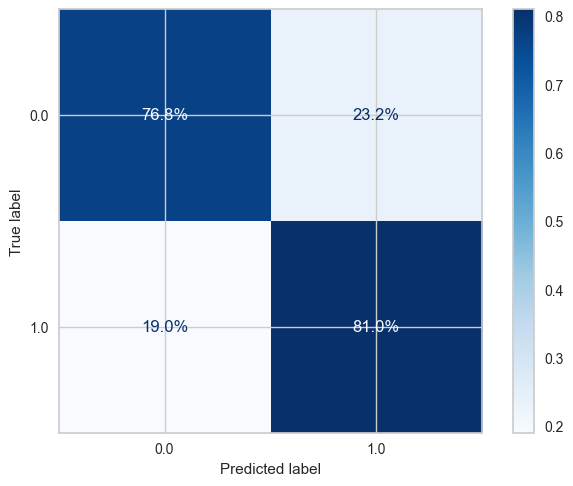

,Protein ID,GO ID,Ground Truth Label,Predicted Label,Probability
0,A2RRP1,GO:0008152,1.0,1.0,0.573057
1,A2RRP1,GO:0034655,1.0,0.0,0.441986
2,A2RRP1,GO:1902373,1.0,1.0,0.673976
3,A2RRP1,GO:0051179,1.0,1.0,0.872691
4,A2RRP1,GO:0016070,1.0,1.0,0.837799
...,...,...,...,...,...
148465,Q15054,GO:0097525,0.0,1.0,0.796228
148466,Q8IX07,GO:0062207,0.0,1.0,0.630284
148467,Q5VWQ8,GO:0070982,0.0,0.0,0.016078
148468,Q16620,GO:0043699,0.0,0.0,0.409373


In [142]:
# Evaluate test set

model.load_state_dict(torch.load(save_path / "best_model_weights.pt"))

test_results = evaluate_model_performance(
    model, protgo_dataset.hetero_data, associations_df, go_ids_map, save_path,
)

test_results

In [143]:
# Extract attention weights

results, plots = plot_node_importance(
    model=model,
    hetero_data=protgo_dataset.hetero_data,
    save_path=save_path,
    top_n=25,
)

# plots
for fig in plots:
    fig.show()

Top nodes by importance for protein_1:
['P04637', 'P19387', 'P10275', 'Q9BTM9', 'P46937', 'O60341', 'P00533', 'Q9Y4K3', 'P35222', 'P63208', 'Q8WXX7', 'Q8N3Y1', 'Q03135', 'Q9UJX5', 'P63165', 'O60356', 'Q6P1J9', 'Q16531', 'Q15653', 'P36405', 'Q92793', 'P38398', 'P06400', 'P28223', 'P04049']
Top nodes by importance for protein_2:
['P04637', 'P19387', 'P10275', 'Q9BTM9', 'P46937', 'O60341', 'P00533', 'Q9Y4K3', 'P35222', 'P63208', 'Q8WXX7', 'Q8N3Y1', 'Q9UJX5', 'Q03135', 'P63165', 'Q6P1J9', 'O60356', 'Q16531', 'Q15653', 'P36405', 'Q92793', 'P06400', 'P38398', 'P28223', 'P04049']
Top nodes by importance for go_1:
['GO:1905297', 'GO:0002848', 'GO:2000700', 'GO:0070610', 'GO:1901095', 'GO:1901714', 'GO:0140429', 'GO:0141150', 'GO:1905014', 'GO:2001158', 'GO:1901956', 'GO:1901076', 'GO:1904457', 'GO:0032209', 'GO:1904214', 'GO:0061003', 'GO:2000947', 'GO:0060493', 'GO:1900485', 'GO:0002847', 'GO:0045542', 'GO:0061890', 'GO:0051894', 'GO:0061297', 'GO:2000920']
Top nodes by importance for go_2:
[

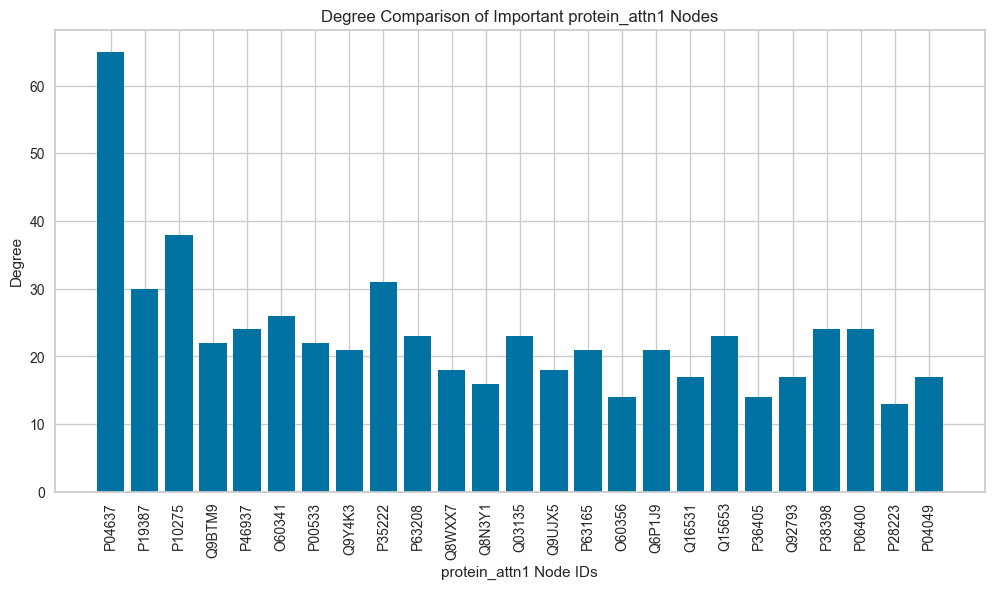

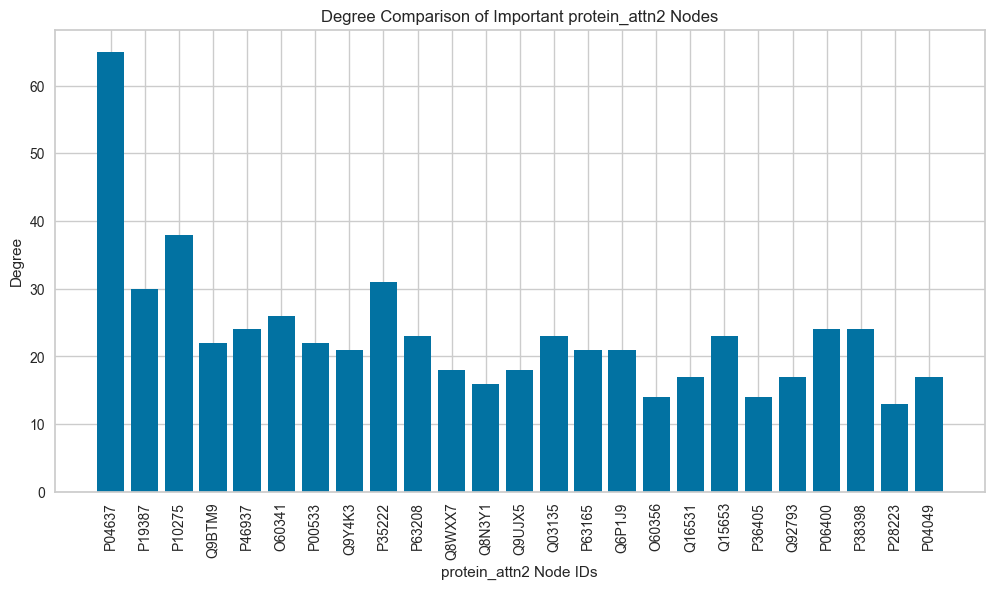

,Node ID,Degree
0,P04637,65.0
1,P19387,30.0
2,P10275,38.0
3,Q9BTM9,22.0
4,P46937,24.0
5,O60341,26.0
6,P00533,22.0
7,Q9Y4K3,21.0
8,P35222,31.0
9,P63208,23.0


In [144]:
# Compare degrees

protein_mapping = {v: k for k, v in protein_ids_map.items()}

compare_degrees(
    results["protein_1"],
    "protein_attn1",
    protgo_dataset.hetero_data["protein", "ppi", "protein"].edge_index,
    protein_mapping,
    save_path,
)

compare_degrees(
    results["protein_2"],
    "protein_attn2",
    protgo_dataset.hetero_data["protein", "ppi", "protein"].edge_index,
    protein_mapping,
    save_path,
)

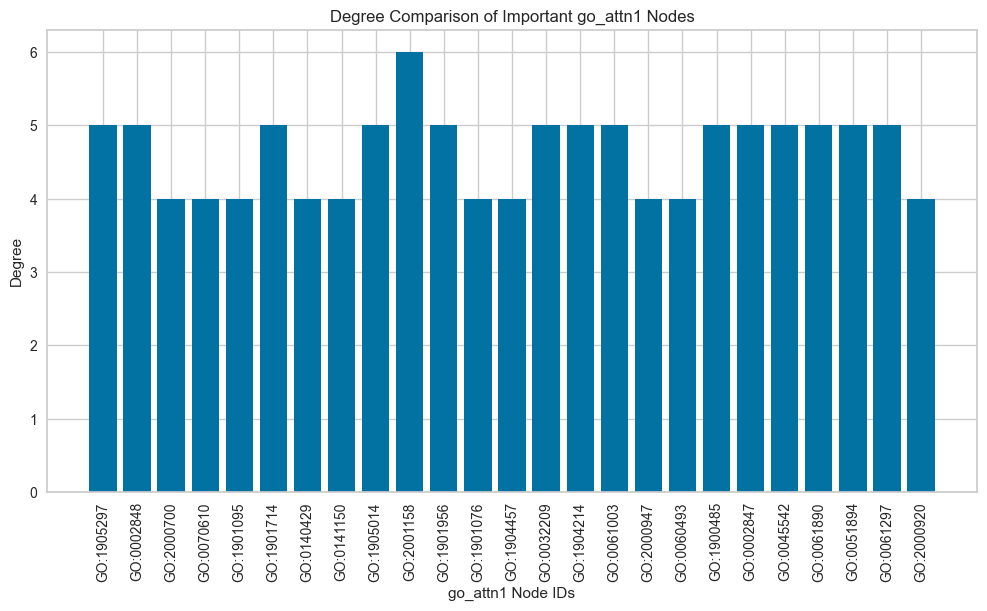

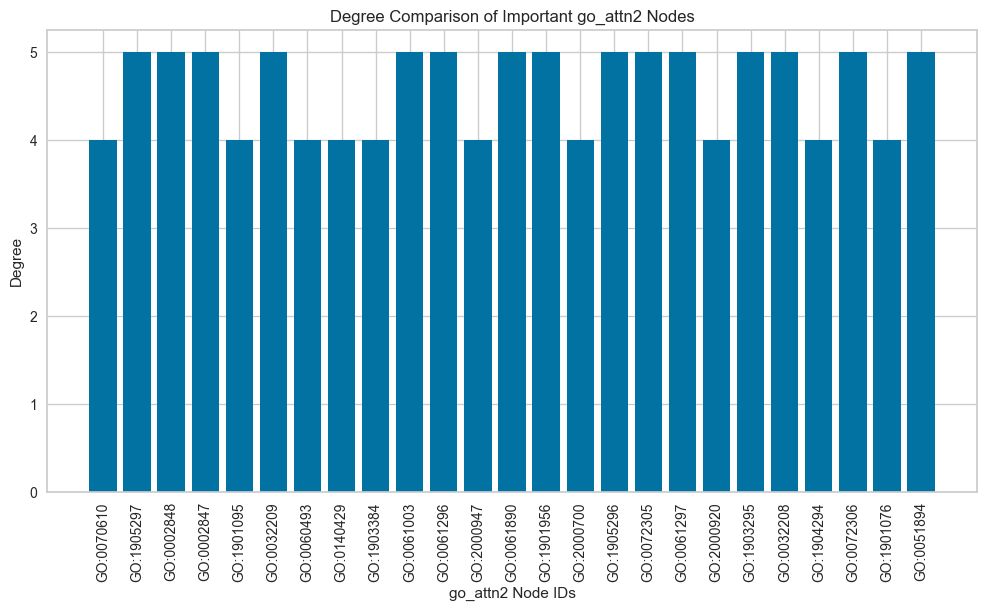

,Node ID,Degree
0,GO:0070610,4.0
1,GO:1905297,5.0
2,GO:0002848,5.0
3,GO:0002847,5.0
4,GO:1901095,4.0
5,GO:0032209,5.0
6,GO:0060493,4.0
7,GO:0140429,4.0
8,GO:1903384,4.0
9,GO:0061003,5.0


In [145]:
# Compare GO degrees

# Convert id mapping to index based mapping

go_mapping = {v:k for k,v in go_ids_map.items()}

compare_degrees(
    results["go_1"],
    "go_attn1",
    protgo_dataset.hetero_data["go", "relation", "go"].edge_index,
    go_mapping,
    save_path,
)

compare_degrees(
    results["go_2"],
    "go_attn2",
    protgo_dataset.hetero_data["go", "relation", "go"].edge_index,
    go_mapping,
    save_path,
)

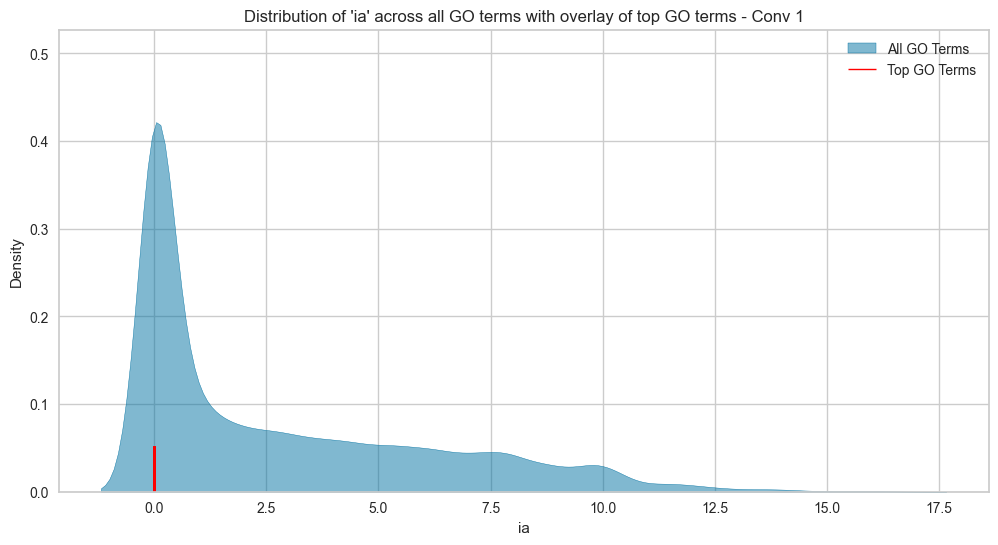

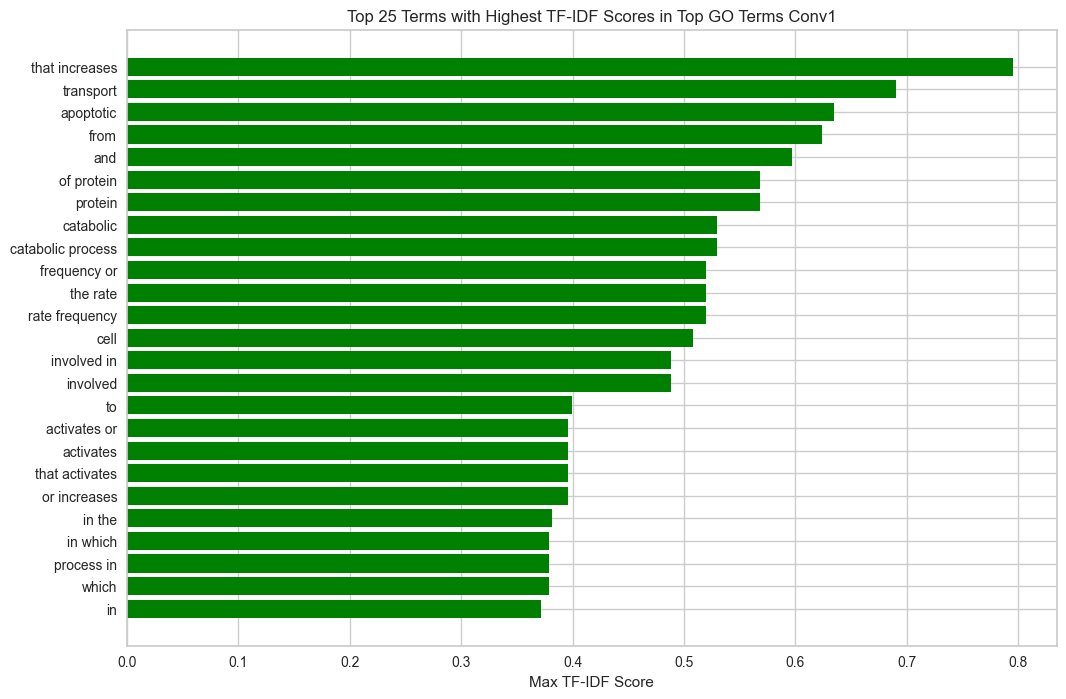

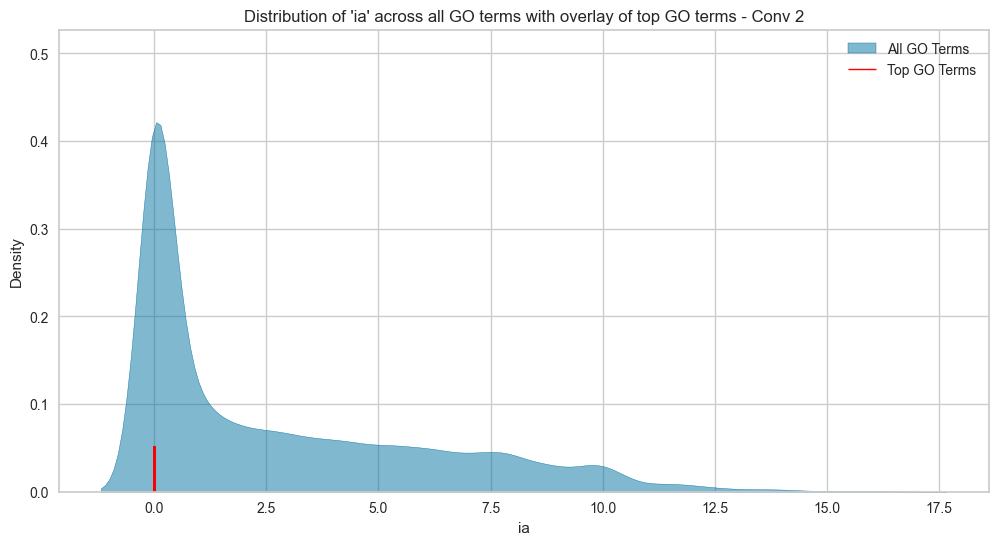

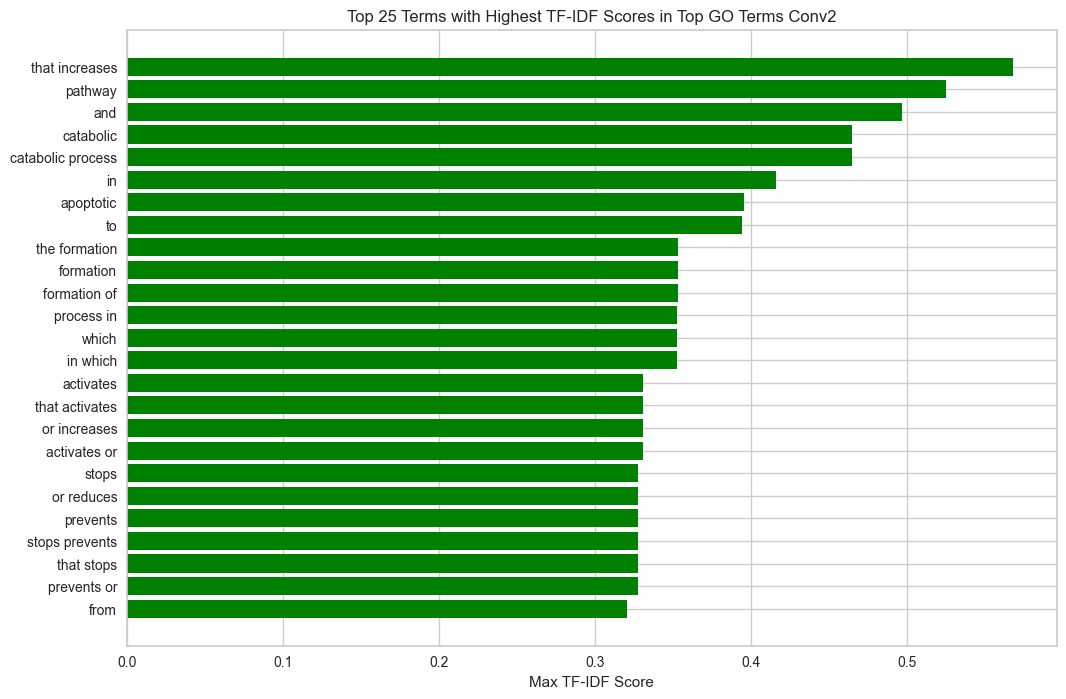

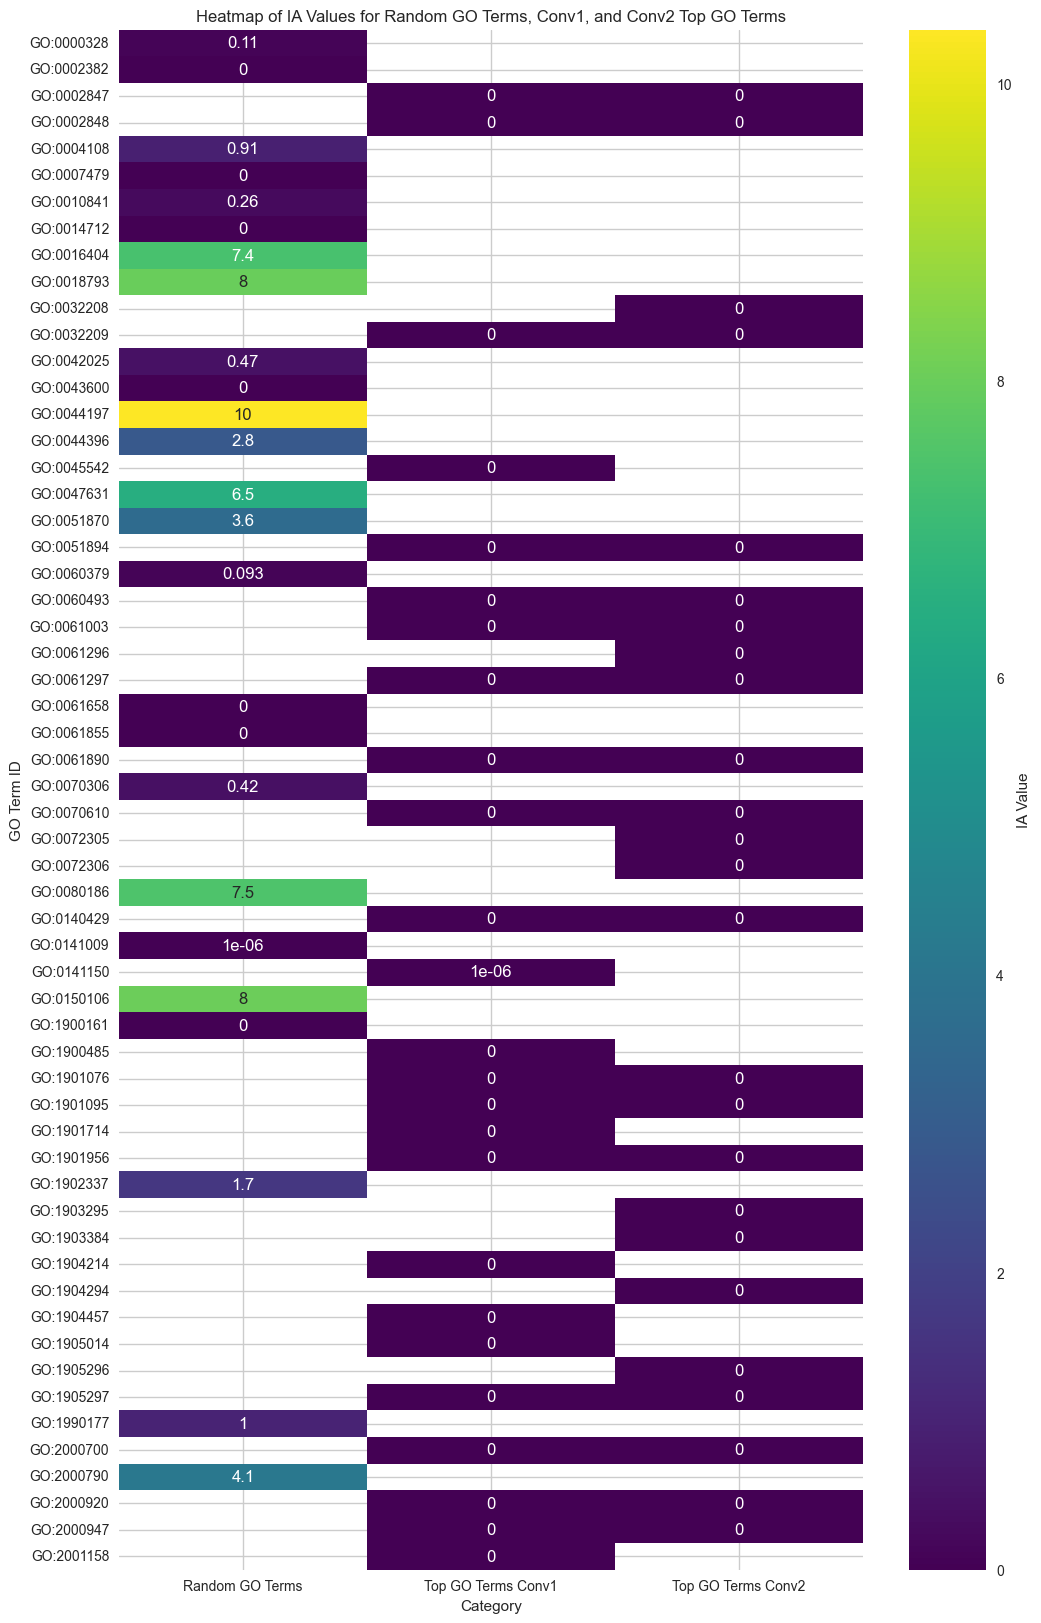

Top tokens in Conv1: ['that increases', 'transport', 'apoptotic', 'from', 'and', 'of protein', 'protein', 'catabolic', 'catabolic process', 'frequency or', 'the rate', 'rate frequency', 'cell', 'involved in', 'involved', 'to', 'activates or', 'activates', 'that activates', 'or increases', 'in the', 'in which', 'process in', 'which', 'in']


,go_id,name,namespace,definition,def_word_count,ia,degree,concat_text,concat_text_word_count
1862,GO:0002847,negative regulation of T cell tolerance induct...,biological_process,"Any process that stops, prevents, or reduces t...",20,0.0,5,negative regulation of T cell tolerance induct...,31
1863,GO:0002848,positive regulation of T cell tolerance induct...,biological_process,Any process that activates or increases the fr...,19,0.0,5,positive regulation of T cell tolerance induct...,30
13258,GO:0032209,positive regulation of telomere maintenance vi...,biological_process,Any process that activates or increases the fr...,23,0.0,5,positive regulation of telomere maintenance vi...,31
19944,GO:0045542,positive regulation of cholesterol biosyntheti...,biological_process,Any process that activates or increases the fr...,23,0.0,5,positive regulation of cholesterol biosyntheti...,30
24510,GO:0051894,positive regulation of focal adhesion assembly,biological_process,Any process that activates or increases the fr...,22,0.0,5,positive regulation of focal adhesion assembly...,29



Top tokens in Conv2: ['that increases', 'pathway', 'and', 'catabolic', 'catabolic process', 'in', 'apoptotic', 'to', 'the formation', 'formation', 'formation of', 'process in', 'which', 'in which', 'activates', 'that activates', 'or increases', 'activates or', 'stops', 'or reduces', 'prevents', 'stops prevents', 'that stops', 'prevents or', 'from']


,go_id,name,namespace,definition,def_word_count,ia,degree,concat_text,concat_text_word_count
1862,GO:0002847,negative regulation of T cell tolerance induct...,biological_process,"Any process that stops, prevents, or reduces t...",20,0.0,5,negative regulation of T cell tolerance induct...,31
1863,GO:0002848,positive regulation of T cell tolerance induct...,biological_process,Any process that activates or increases the fr...,19,0.0,5,positive regulation of T cell tolerance induct...,30
13257,GO:0032208,negative regulation of telomere maintenance vi...,biological_process,"Any process that stops, prevents, or reduces t...",24,0.0,5,negative regulation of telomere maintenance vi...,32
13258,GO:0032209,positive regulation of telomere maintenance vi...,biological_process,Any process that activates or increases the fr...,23,0.0,5,positive regulation of telomere maintenance vi...,31
24510,GO:0051894,positive regulation of focal adhesion assembly,biological_process,Any process that activates or increases the fr...,22,0.0,5,positive regulation of focal adhesion assembly...,29


In [146]:
# Inspect top GO terms

top_tokens_conv1, top_tokens_conv2, top_go_df_conv1, top_go_df_conv2 = analyze_top_go(
    go_df, results, information_accretion_col="ia", text_col="definition", top_n=25
)

print(f"Top tokens in Conv1: {top_tokens_conv1}")
display(top_go_df_conv1.head())

print(f"\nTop tokens in Conv2: {top_tokens_conv2}")
display(top_go_df_conv2.head())

### GAT Model + Regularization

In [ ]:
# Model Class


class HGNNGAT(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
    ):
        super(HGNNGAT, self).__init__()
        # Calculate the number of output features per head
        per_head_features = out_features // heads if concat else out_features

        # Initialize GAT layers for each type of connection with multi-head attention
        self.conv1_protein = GATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
        )
        self.conv1_go = GATConv(
            go_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_protein = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_go = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )

        # Adjust the output feature size based on concatenation or averaging of heads
        final_out_features = out_features if concat else per_head_features

        # Dropout layer
        self.dropout = Dropout(dropout)

        # Linear layer for making predictions
        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        # Apply the first convolution layer to protein and GO nodes
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )

        # Apply dropout
        x_protein = self.dropout(x_protein)
        x_go = self.dropout(x_go)

        # Apply the second convolution layer
        x_protein = F.elu(
            self.conv2_protein(
                x_protein, edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))

        # Apply dropout
        x_protein = self.dropout(x_protein)
        x_go = self.dropout(x_go)

        # Handling edges based on the mask
        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]

        # Concatenate features from proteins and GOs
        association_features = torch.cat([protein_features, go_features], dim=1)

        # Predict association
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores

    def get_attention_weights(self, x_dict, edge_index_dict):
        self.eval()
        with torch.no_grad():
            # Get attention weights from the first GAT layer for protein nodes
            x_protein, (edge_index_protein_1, attn_weights_protein_1) = (
                self.conv1_protein(
                    x_dict["protein"],
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            # Get attention weights from the second GAT layer for protein nodes
            x_protein, (edge_index_protein_2, attn_weights_protein_2) = (
                self.conv2_protein(
                    x_protein,
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )

            # Get attention weights from the first GAT layer for GO nodes
            x_go, (edge_index_go_1, attn_weights_go_1) = self.conv1_go(
                x_dict["go"],
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )
            # Get attention weights from the second GAT layer for GO nodes
            x_go, (edge_index_go_2, attn_weights_go_2) = self.conv2_go(
                x_go,
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            # Return all attention weights
            return (
                (edge_index_protein_1, attn_weights_protein_1),
                (edge_index_go_1, attn_weights_go_1),
                (edge_index_protein_2, attn_weights_protein_2),
                (edge_index_go_2, attn_weights_go_2),
            )

In [ ]:
# Training and loggint to W&B

# Clean CUDA
torch.cuda.empty_cache()

# Capture dict of hyperparameters
config = {
    "lr": 0.0001,
    "epochs": 200,
    "batch_size": 10000,
    "dropout_rate": 0.5,
    "heads": 8,
    "out_features": 512,
    "weight_decay": 1e-6,
    "scheduler_patience": 10,
    "early_stopping_patience": 10,
    "clip": 1.0,  # Gradient clipping value
}

# Initialize run
run = wandb.init(
    project="prot2go",
    notes="Baseline GAT Model",
    tags=[
        "baseline",
        "regularization do and gc",
        "out features 512",
        "human",
        "data_balance > 1:2",
        "go text: concat",
        "data split train 0.6",
        "clipping",
    ],
    config=config,
    # mode="disabled"
)


# Training loop
def train(
    model,
    dataset,
    save_path=None,
    device="cuda" if torch.cuda.is_available() else "cpu",
):

    # Send model and data to GPU if available
    model.to(device)
    dataset.to_device(device)
    dataset.create_data_loaders(batch_size=config["batch_size"])

    optimizer = torch.optim.Adam(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        "min",
        patience=config["scheduler_patience"],
        factor=0.1,
        verbose=True,
    )

    best_val_loss = float("inf")
    early_stopping_counter = 0

    # Training loop
    for epoch in tqdm(
        range(1, config["epochs"] + 1), desc="Training...", total=config["epochs"]
    ):
        model.train()
        train_loss = 0
        train_predictions = []
        train_labels = []

        # Assume dataset.train_loader is correctly set up
        for edge_index, edge_label in dataset.train_loader:
            optimizer.zero_grad()
            edge_index = edge_index.to(device)
            edge_label = edge_label.to(device)

            # Model predictions
            out = model(
                {
                    "protein": dataset.hetero_data["protein"].x,
                    "go": dataset.hetero_data["go"].x,
                },
                {
                    ("protein", "ppi", "protein"): dataset.hetero_data[
                        "protein", "ppi", "protein"
                    ].edge_index,
                    ("go", "relation", "go"): dataset.hetero_data[
                        "go", "relation", "go"
                    ].edge_index,
                    ("protein", "associates_with", "go"): edge_index.t(),
                },
            )
            loss = F.binary_cross_entropy_with_logits(out, edge_label)
            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), config["clip"])

            optimizer.step()

            train_loss += loss.item()
            train_predictions.append(out.sigmoid().detach().cpu().numpy())
            train_labels.append(edge_label.cpu().numpy())

        # Log training metrics
        train_loss /= len(dataset.train_loader)
        train_auroc = roc_auc_score(
            np.concatenate(train_labels), np.concatenate(train_predictions)
        )
        wandb.log({"train_loss": train_loss, "train_auroc": train_auroc})

        # Validation step
        model.eval()
        with torch.no_grad():
            val_loss = 0
            val_predictions = []
            val_labels = []

            for edge_index, edge_label in dataset.val_loader:
                edge_index = edge_index.to(device)
                edge_label = edge_label.to(device)

                out = model(
                    {
                        "protein": dataset.hetero_data["protein"].x,
                        "go": dataset.hetero_data["go"].x,
                    },
                    {
                        ("protein", "ppi", "protein"): dataset.hetero_data[
                            "protein", "ppi", "protein"
                        ].edge_index,
                        ("go", "relation", "go"): dataset.hetero_data[
                            "go", "relation", "go"
                        ].edge_index,
                        ("protein", "associates_with", "go"): edge_index.t(),
                    },
                )
                loss = F.binary_cross_entropy_with_logits(out, edge_label)
                val_loss += loss.item()
                val_predictions.append(out.sigmoid().cpu().numpy())
                val_labels.append(edge_label.cpu().numpy())

            val_loss /= len(dataset.val_loader)
            val_auroc = roc_auc_score(
                np.concatenate(val_labels), np.concatenate(val_predictions)
            )
            wandb.log({"val_loss": val_loss, "val_auroc": val_auroc})

            # Early stopping logic
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                torch.save(model.state_dict(), f"{save_path}/best_model_weights.pt")
                early_stopping_counter = 0
            else:
                early_stopping_counter += 1

            if early_stopping_counter >= config["early_stopping_patience"]:
                print(f"Early stopping triggered after {epoch} epochs.")
                break

        scheduler.step(val_loss)

        if epoch % 10 == 0:
            print(
                f"Epoch {epoch}: Train Loss: {train_loss:.3f}, Train AUROC: {train_auroc:.3f}, Val Loss: {val_loss:.3f}, Val AUROC: {val_auroc:.3f}"
            )


# Create and train the model
model = HGNNGAT(
    protein_features=1024,
    go_features=384,
    out_features=config["out_features"],
    dropout=config["dropout_rate"],
    heads=config["heads"],
)
wandb.watch(model, log="all", log_freq=10)

save_path = species_folder / "models/baseline_gpu_out_512_r"
save_path.mkdir(parents=True, exist_ok=True)

train(model=model, dataset=protgo_dataset, save_path=save_path)
wandb.finish()

In [ ]:
# Evaluate test set

model.load_state_dict(torch.load(save_path / "best_model_weights.pt"))

test_results = evaluate_model_performance(
    model, protgo_dataset.hetero_data, associations_df, go_ids_map, save_path,
)

test_results

In [ ]:
# Extract attention weights

results, plots = plot_node_importance(
    model=model,
    hetero_data=protgo_dataset.hetero_data,
    save_path=save_path,
    top_n=25,
)

# plots
for fig in plots:
    fig.show()

In [ ]:
# Compare degrees

protein_mapping = {v: k for k, v in protein_ids_map.items()}

compare_degrees(
    results["protein_1"],
    "protein_attn1",
    protgo_dataset.hetero_data["protein", "ppi", "protein"].edge_index,
    protein_mapping,
    save_path,
)

compare_degrees(
    results["protein_2"],
    "protein_attn2",
    protgo_dataset.hetero_data["protein", "ppi", "protein"].edge_index,
    protein_mapping,
    save_path,
)

In [ ]:
# Compare GO degrees

# Convert id mapping to index based mapping

go_mapping = {v:k for k,v in go_ids_map.items()}

compare_degrees(
    results["go_1"],
    "go_attn1",
    protgo_dataset.hetero_data["go", "relation", "go"].edge_index,
    go_mapping,
    save_path,
)

compare_degrees(
    results["go_2"],
    "go_attn2",
    protgo_dataset.hetero_data["go", "relation", "go"].edge_index,
    go_mapping,
    save_path,
)

In [ ]:
# Inspect top GO terms

top_tokens_conv1, top_tokens_conv2, top_go_df_conv1, top_go_df_conv2 = analyze_top_go(
    go_df, results, information_accretion_col="ia", text_col="definition", top_n=25
)

print(f"Top tokens in Conv1: {top_tokens_conv1}")
display(top_go_df_conv1.head())

print(f"\nTop tokens in Conv2: {top_tokens_conv2}")
display(top_go_df_conv2.head())